# SFSC 2026 — V3: 4-fold UNet (EfficientNetV2-S) + soft multi-annotator targets + contact head + OOF-calibrated instance extraction (Colab / NVIDIA L4)

**What changes vs V2 (and why)**

| Area | V2 | V3 | Reason |
|---|---|---|---|
| Data use | 498 train JPEGs, 106 dev for calibration, 103 holdout unused | **4-fold grouped CV (date + hash)**: every fold trains on ~530 JPEGs; calibration on **out-of-fold predictions for all 707 JPEGs**; test = 4-model ensemble | 42% more training data per model, 6.7x more calibration images |
| Compute | batch 2, 384 crops/epoch, ~30 min total, 2.4 GiB peak | effective batch 8 (auto micro-batch), 2,000 crops/epoch x 40 epochs per fold, BN trained, EMA 0.999 | V2 saw each pixel ~5x and was still improving |
| Targets | one random annotator record per sample | **soft target = mean of all annotators' masks** + **contact-boundary target** | identical expected BCE gradient, zero annotator-sampling variance |
| Model | DeepLabV3+ ResNet50, logits at 1/4 resolution | **UNet + EfficientNetV2-S** (stride-2 and full-res decoder), scSE attention, 2 outputs | 8-px-wide filaments get 2 logit cells at stride 4; 1-2 px boundary error = IoU 0.75-0.5 |
| Input | 1 grayscale channel | **3 channels: raw, limb-darkening-flattened, radial position r/R** | crops do not know where on the disk they are; appearance depends on r |
| Loss | 0.5 BCE + Tversky(0.65 FP) + 0.2 edge | 0.5 BCE(soft) + **Lovász hinge** + 0.2 edge + 0.5 contact BCE (+ optional clDice) | Lovász is a convex IoU surrogate (=SQ); V2's FP-bias now costs recall (FN 453 > FP 366) |
| Augmentation | flips/rot90, CLAHE .25 | + free rotation, mild scale, wider gamma, flattened-channel jitter | solar disk has no preferred orientation |
| Inference | identity, tile 640/512 | **8-fold D4 TTA**, tile 1024/768, 4-fold ensemble | real model ensembling, fewer seams |
| Instances | threshold -> CC -> area/mean filter | **hysteresis** (seed + extent thresholds), **hole filling**, **±1 px boundary offset**, optional **contact-split**, then **grid filter or learned IoU-contribution scorer** (keep if E[IoU·1(match)] > τ ≈ PQ/2) | separates the keep decision from mask extent |
| Checkpoint selection | fixed recipe (0.70/128) ≠ final recipe | **calibrated PQ** at every evaluation | V2's fixed-recipe 0.319 vs calibrated 0.401 |
| Logging | loss + fixed-recipe PQ | throughput, data-wait, grad-norm, LR, memory, P/R, calibrated recipe; **error decomposition** (missed / near-miss / merged / fragmented by size & radius); **oracle ceilings** (CC-of-GT, inter-annotator PQ) | tells V4 where the remaining PQ is |

### Run order
1. **Runtime -> Change runtime type -> L4 GPU** (High-RAM if offered).
2. Dataset ZIP stays where V1/V2 used it: `MyDrive/SFSC2026/data/sfsc2026-data.zip` (or the extracted `SFSCDataset` folder).
3. **Runtime -> Run all.** Stages: caches -> folds -> label diagnostics -> train fold 0..3 -> OOF prediction -> calibration -> scorer -> error report -> test ensemble -> `submission.csv`.
4. If Colab disconnects or hits a session limit: reconnect and **Run all again**. Finished folds, the current fold's `last.pt`, OOF maps, calibration and scorer are all on Drive and are reused; nothing is redone.
5. Submit `MyDrive/SFSC2026/outputs/sfsc_unet_v3/test_export/submission.csv`.

Optional: set `CFG.debug_run = True` in Cell 03 for a ~15-minute end-to-end pipeline check (1 fold, 2 short epochs, separate `_debug` folder). Set it back to `False` for the real run.

Rough L4 budget (estimate, not benchmarked): ~60-75 min per fold incl. evaluation, ~25 min OOF TTA, ~10 min calibration, ~25 min test ensemble -> **~5-6 h total**, resumable at any point.

*Notebook was written without being executed against the real dataset. Report any error with the cell number and traceback.*

## Cell 01 — Mount Drive and choose the V3 run folder

*   List item
*   List item



In [2]:
from pathlib import Path
import os

IN_COLAB = bool(os.environ.get("COLAB_RELEASE_TAG"))
DRIVE_ROOT = Path("/content/drive/MyDrive/SFSC2026")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

DATA_ZIP = DRIVE_ROOT / "data" / "sfsc2026-data.zip"
DRIVE_EXTRACTED = DRIVE_ROOT / "data" / "SFSCDataset"
V1_SPLIT_CSV = DRIVE_ROOT / "outputs" / "sfsc_deeplabv3_clahe_v1" / "split.csv"   # only for V2-comparable reporting
V3_RUN_BASE = DRIVE_ROOT / "outputs" / "sfsc_unet_v3"
LOCAL_ROOT = Path("/content/sfsc_v3") if IN_COLAB else Path("/tmp/sfsc_v3")
LOCAL_DATA = LOCAL_ROOT / "dataset"
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
print("V3 output base:", V3_RUN_BASE)
print("Dataset ZIP:", DATA_ZIP)

Mounted at /content/drive
V3 output base: /content/drive/MyDrive/SFSC2026/outputs/sfsc_unet_v3
Dataset ZIP: /content/drive/MyDrive/SFSC2026/data/sfsc2026-data.zip


## Cell 02 — Install missing dependencies (keeps Colab's CUDA PyTorch)

In [3]:
import importlib.util, subprocess, sys

REQUIRED = {
    "segmentation_models_pytorch": "segmentation-models-pytorch>=0.3.4",
    "timm": "timm>=0.9.16",
    "sklearn": "scikit-learn>=1.3",
    "pycocotools": "pycocotools>=2.0.7",
    "cv2": "opencv-python-headless>=4.8",
    "scipy": "scipy>=1.10",
    "pandas": "pandas>=2.0",
    "tqdm": "tqdm>=4.66",
    "matplotlib": "matplotlib>=3.7",
}
missing = [pkg for module, pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
import torch, torchvision, timm, sklearn
import segmentation_models_pytorch as smp
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| timm", timm.__version__,
      "| smp", smp.__version__, "| sklearn", sklearn.__version__)

Installing: ['segmentation-models-pytorch>=0.3.4']
torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | timm 1.0.30 | smp 0.5.0 | sklearn 1.6.1


## Cell 03 — Imports, configuration (edit here), reproducibility and helpers

In [4]:
import contextlib, copy, gc, hashlib, json, math, multiprocessing as mp, pickle, platform
import random, re, shutil, tempfile, time, warnings, zipfile
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor
from dataclasses import dataclass, asdict, field
from functools import lru_cache
from itertools import product

import cv2
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from pycocotools import mask as mask_api
from sklearn.ensemble import HistGradientBoostingRegressor
from tqdm.auto import tqdm
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

cv2.setNumThreads(1)
D4_OPS = ("r0", "r1", "r2", "r3", "r0f", "r1f", "r2f", "r3f")

@dataclass
class Config:
    # ---- run control ----
    debug_run: bool = False                  # True = quick pipeline check (separate *_debug folder)
    local_dataset_override: str | None = None
    expected_shape: tuple = (2048, 2048)
    seed: int = 20261011
    n_folds: int = 4
    folds_to_train: tuple = (0, 1, 2, 3)
    group_by_date: bool = True
    export_test: bool = True

    # ---- solar-disk geometry and input channels ----
    # disk_radius_fraction: float = 1036 / 1024   # disk edge radius / (image size / 2); centre = image centre
    disk_radius_fraction: float = 0.88
    radial_bins: int = 512
    flat_median_kernel: int = 41                 # at 1/4 resolution of 2048 px (~164 native px)
    flat_std: float = 0.15
    contact_radius: int = 2                      # px dilation used to define touching-instance zones

    # ---- model ----
    architecture: str = "Unet"
    encoder_name: str = "tu-tf_efficientnetv2_s.in21k_ft_in1k"
    encoder_fallbacks: tuple = ("tu-tf_efficientnetv2_s", "efficientnet-b4", "resnet50")
    decoder_attention: str | None = "scse"

    # ---- training ----
    crop_size: int = 768
    effective_batch: int = 8
    microbatch_candidates: tuple = (8, 4, 2)
    steps_per_epoch: int = 250                    # optimizer steps -> 2,000 crops / epoch
    epochs: int = 40
    workers: int | None = None
    prefetch_factor: int = 4
    amp: bool = True
    channels_last: bool = True
    encoder_lr: float = 3e-4
    decoder_lr: float = 1e-3
    weight_decay: float = 1e-2
    warmup_epochs: float = 2.0
    min_lr_fraction: float = 0.02
    ema_decay: float = 0.999
    grad_clip: float = 1.0
    eval_start: int = 12
    eval_every: int = 4
    save_every: int = 2

    # ---- crop sampling ----
    p_positive: float = 0.50                       # centred on a random annotated instance (any annotator)
    p_hard_negative: float = 0.25                  # dark, un-annotated on-disk regions
    # remaining 25% uniform random

    # ---- augmentation ----
    p_free_rotation: float = 0.7
    p_scale: float = 0.5
    scale_range: tuple = (0.85, 1.15)
    p_clahe: float = 0.15
    p_blur: float = 0.10
    p_gamma: float = 0.30
    gamma_range: tuple = (0.80, 1.25)
    p_brightness_contrast: float = 0.40
    brightness: float = 0.04
    contrast: float = 0.10
    p_noise: float = 0.15
    noise_std: float = 0.012
    p_flat_jitter: float = 0.30

    # ---- loss ----
    bce_weight: float = 0.5
    pos_weight: float = 1.0
    lovasz_weight: float = 1.0
    edge_weight: float = 0.2
    contact_weight: float = 0.5
    contact_pos_weight: float = 3.0
    cldice_weight: float = 0.0                     # ablation switch (fragmentation); 0 = off
    cldice_iters: int = 6

    # ---- inference ----
    tile: int = 1024
    stride: int = 768
    infer_batch: int = 4
    tta_eval: tuple = ("r0",)
    tta_final: tuple = D4_OPS

    # ---- instance extraction / calibration grid (all on uint8 probability maps) ----
    connectivity: int = 8
    fill_holes: bool = True
    min_core_area: int = 16
    contact_assign_radius: float = 6.0
    grid_t_low: tuple = (0.30, 0.40, 0.50)
    grid_contact: tuple = (None, 0.5)
    grid_offset: tuple = (-1, 0, 1)
    grid_t_high: tuple = (0.5, 0.6, 0.7, 0.8, 0.9)
    grid_mean: tuple = (0.0, 0.5, 0.6, 0.7, 0.8)
    grid_area: tuple = (0, 32, 64, 128, 256)
    eval_t_low: tuple = (0.40, 0.50)               # small grid used during training for checkpoint selection
    eval_t_high: tuple = (0.6, 0.7, 0.8)
    eval_mean: tuple = (0.0, 0.6, 0.7)
    eval_area: tuple = (0, 64)

    # ---- learned instance scorer ----
    use_learned_scorer: bool = True
    scorer_prefilter_max: float = 0.40
    scorer_prefilter_area: int = 16
    scorer_taus: tuple = tuple(np.round(np.arange(0.05, 0.551, 0.025), 3))
    scorer_min_gain: float = 0.002                 # scorer must beat the grid by this OOF PQ to be used

    cpu_pool_workers: int | None = None

CFG = Config()

if CFG.debug_run:
    CFG.folds_to_train = (0,)
    CFG.epochs, CFG.steps_per_epoch = 2, 20
    CFG.eval_start, CFG.eval_every = 1, 1
    CFG.tta_final = ("r0", "r2f")
DEBUG_EVAL_LIMIT = 12 if CFG.debug_run else None

RUN = V3_RUN_BASE.with_name(V3_RUN_BASE.name + ("_debug" if CFG.debug_run else ""))
RUN.mkdir(parents=True, exist_ok=True)

assert CFG.crop_size % 32 == 0 and CFG.tile % 32 == 0 and 0 < CFG.stride <= CFG.tile
assert CFG.effective_batch % min(CFG.microbatch_candidates) == 0
assert 0 <= CFG.p_positive + CFG.p_hard_negative <= 1
assert set(CFG.tta_final) <= set(D4_OPS) and set(CFG.tta_eval) <= set(D4_OPS)
assert all(f in range(CFG.n_folds) for f in CFG.folds_to_train)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("V3 needs a CUDA GPU. Runtime -> Change runtime type -> L4.")
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision("high")
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
AMP_ENABLED = CFG.amp
random.seed(CFG.seed); np.random.seed(CFG.seed); torch.manual_seed(CFG.seed); torch.cuda.manual_seed_all(CFG.seed)

CPU_COUNT = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 2)
WORKERS = min(8, max(1, CPU_COUNT - 2)) if CFG.workers is None else CFG.workers
CPU_POOL = max(2, CPU_COUNT - 2) if CFG.cpu_pool_workers is None else CFG.cpu_pool_workers

def hash_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for part in iter(lambda: f.read(1 << 20), b""):
            h.update(part)
    return h.hexdigest()

def object_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":"), default=str).encode()).hexdigest()

def write_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    fd, temp = tempfile.mkstemp(prefix=".json_", dir=str(path.parent))
    try:
        with os.fdopen(fd, "w") as f:
            json.dump(obj, f, indent=2, default=str)
        os.replace(temp, path)
    finally:
        Path(temp).unlink(missing_ok=True)

def save_npy_atomic(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    fd, temp = tempfile.mkstemp(prefix=".npy_", dir=str(path.parent))
    try:
        with os.fdopen(fd, "wb") as f:
            np.save(f, value, allow_pickle=False)
        os.replace(temp, path)
    finally:
        Path(temp).unlink(missing_ok=True)

def copy_atomic(src, dst):
    src, dst = Path(src), Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.is_file() and dst.stat().st_size == src.stat().st_size:
        return
    temp = dst.with_suffix(dst.suffix + ".part")
    shutil.copyfile(src, temp)
    os.replace(temp, dst)

def autocast_context():
    return torch.autocast("cuda", dtype=AMP_DTYPE) if AMP_ENABLED else contextlib.nullcontext()

print("GPU:", torch.cuda.get_device_name(0), "| AMP:", AMP_DTYPE if AMP_ENABLED else "off")
print("CPU cores:", CPU_COUNT, "| DataLoader workers:", WORKERS, "| CPU scoring pool:", CPU_POOL)
print("Run folder:", RUN, "| debug_run =", CFG.debug_run)

GPU: NVIDIA L4 | AMP: torch.bfloat16
CPU cores: 12 | DataLoader workers: 8 | CPU scoring pool: 10
Run folder: /content/drive/MyDrive/SFSC2026/outputs/sfsc_unet_v3 | debug_run = False


## Cell 04 — Stage the dataset on the local Colab SSD

In [5]:
ANNOTATION_BASENAME = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
LOCAL_ZIP = LOCAL_ROOT / "sfsc_dataset.zip"

def locate_dataset(root):
    root = Path(root)
    hits = sorted(root.rglob(ANNOTATION_BASENAME)) if root.is_dir() else []
    if len(hits) != 1:
        raise FileNotFoundError(f"Expected one {ANNOTATION_BASENAME} under {root}; found {len(hits)}")
    ann = hits[0]
    train_dir = ann.parent / "train_images"
    test_dir = ann.parent.parent / "test" / "test_images"
    if not (train_dir.is_dir() and test_dir.is_dir()):
        raise FileNotFoundError(f"Missing train_images or test_images near {ann}")
    return ann, train_dir, test_dir

def image_paths(folder):
    return {p.name: p for p in Path(folder).iterdir()
            if p.is_file() and p.suffix.lower() in (".jpg", ".jpeg")}

def staged_and_ready(root):
    try:
        a, t, s = locate_dataset(root)
        return a.stat().st_size > 1000 and len(image_paths(t)) > 0 and len(image_paths(s)) > 0
    except (FileNotFoundError, OSError):
        return False

def safe_extract(zip_path, destination):
    destination.mkdir(parents=True, exist_ok=True)
    resolved_root = destination.resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for member in tqdm(archive.infolist(), desc="Extract dataset"):
            if member.is_dir():
                continue
            dest = (destination / member.filename).resolve()
            if not dest.is_relative_to(resolved_root):
                raise ValueError(f"Unsafe ZIP member: {member.filename}")
            if dest.is_file() and dest.stat().st_size == member.file_size:
                continue
            dest.parent.mkdir(parents=True, exist_ok=True)
            archive.extract(member, destination)

if CFG.local_dataset_override:
    DATA_ROOT = Path(CFG.local_dataset_override)
    if not staged_and_ready(DATA_ROOT):
        raise FileNotFoundError(f"Dataset override not ready: {DATA_ROOT}")
elif staged_and_ready(LOCAL_DATA):
    DATA_ROOT = LOCAL_DATA
else:
    DATA_ROOT = LOCAL_DATA
    if DATA_ZIP.is_file():
        print("Copying ZIP to local SSD once per runtime...")
        copy_atomic(DATA_ZIP, LOCAL_ZIP)
        safe_extract(LOCAL_ZIP, DATA_ROOT)
    elif DRIVE_EXTRACTED.is_dir():
        print("Copying extracted dataset folder from Drive to local SSD...")
        shutil.copytree(DRIVE_EXTRACTED, DATA_ROOT, dirs_exist_ok=True)
    else:
        raise FileNotFoundError(f"Expected {DATA_ZIP} or {DRIVE_EXTRACTED}. Or set CFG.local_dataset_override.")
if not staged_and_ready(DATA_ROOT):
    raise RuntimeError("Local staging incomplete. Check ZIP contents and free disk space.")

ANN_PATH, TRAIN_DIR, TEST_DIR = locate_dataset(DATA_ROOT)
TRAIN_PATHS, TEST_PATHS = image_paths(TRAIN_DIR), image_paths(TEST_DIR)
for label, paths in (("train", TRAIN_PATHS), ("test", TEST_PATHS)):
    if len({Path(n).stem for n in paths}) != len(paths):
        raise ValueError(f"Duplicate {label} image stems; IDs would collide.")

def read_gray(path):
    with Image.open(path) as im:
        if im.mode == "L":
            return np.asarray(im, dtype=np.uint8).copy()
        if im.mode != "RGB":
            raise ValueError(f"Unexpected image mode {im.mode}: {path}")
        arr = np.asarray(im, dtype=np.uint8)
        d1 = np.abs(arr[:, :, 0].astype(np.int16) - arr[:, :, 1])
        d2 = np.abs(arr[:, :, 0].astype(np.int16) - arr[:, :, 2])
        if d1.max() > 2 or d2.max() > 2:
            raise ValueError(f"Non-grayscale RGB image: {path}")
        return arr[:, :, 0].copy()

RAW = json.loads(ANN_PATH.read_text())
ANN_SHA = hash_file(ANN_PATH)
print("Annotation JSON:", ANN_PATH, "| sha256", ANN_SHA[:16])
print("JPEGs:", len(TRAIN_PATHS), "train /", len(TEST_PATHS), "test | free local GiB:",
      round(shutil.disk_usage(LOCAL_ROOT).free / 2**30, 1))

Copying ZIP to local SSD once per runtime...


Extract dataset:   0%|          | 0/888 [00:00<?, ?it/s]

Annotation JSON: /content/sfsc_v3/dataset/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json | sha256 5da9e92b5a1a1947
JPEGs: 707 train / 180 test | free local GiB: 191.2


## Cell 05 — COCO parsing, record index, integrity inventory

In [6]:
H, W = CFG.expected_shape

def native_rle(rle):
    counts = rle["counts"]
    if isinstance(counts, str):
        counts = counts.encode("ascii")
    return {"size": [int(x) for x in rle["size"]], "counts": counts}

def json_rle(rle):
    counts = rle["counts"]
    return {"size": [int(x) for x in rle["size"]],
            "counts": counts.decode("ascii") if isinstance(counts, bytes) else counts}

def decode_mask(rle):
    a = mask_api.decode(native_rle(rle))
    return np.any(a, axis=2) if a.ndim == 3 else (a > 0)

def segmentation_to_rle(seg, h, w):
    if isinstance(seg, dict):
        if list(seg.get("size", [h, w])) != [h, w]:
            raise ValueError("Annotation RLE shape mismatch")
        rle = (mask_api.frPyObjects(seg, h, w) if isinstance(seg.get("counts"), list)
               else native_rle({"size": [h, w], "counts": seg["counts"]}))
    elif isinstance(seg, list) and len(seg):
        polys = seg if isinstance(seg[0], (list, tuple)) else [seg]
        if any(len(p) < 6 or len(p) % 2 for p in polys):
            raise ValueError("Malformed polygon segmentation")
        rle = mask_api.merge(mask_api.frPyObjects(polys, h, w))
    else:
        raise ValueError("Unsupported empty/malformed segmentation")
    return json_rle(rle)

STEMS = defaultdict(list)
for _n in TRAIN_PATHS:
    STEMS[Path(_n).stem].append(_n)

def canonical_filename(s):
    name = Path(str(s)).name
    if name in TRAIN_PATHS:
        return name
    cands = STEMS.get(Path(name).stem, [])
    if len(cands) == 1:
        return cands[0]
    raise ValueError(f"Unresolvable annotated JPEG: {s}")

IMAGES_BY_ID = {}
for im in RAW["images"]:
    rid = str(im["id"])
    if rid in IMAGES_BY_ID:
        raise ValueError(f"Duplicate image record {rid}")
    if (int(im["height"]), int(im["width"])) != (H, W):
        raise ValueError(f"Unexpected dimensions for record {rid}")
    IMAGES_BY_ID[rid] = im

ANNOTATIONS_BY_ID = defaultdict(list)
_seen = set()
for a in RAW["annotations"]:
    aid, rid = str(a["id"]), str(a["image_id"])
    if aid in _seen or rid not in IMAGES_BY_ID:
        raise ValueError(f"Duplicate annotation or missing image: {aid} / {rid}")
    if int(a.get("iscrowd", 0)):
        raise ValueError(f"Unexpected crowd annotation {aid}")
    if int(a.get("category_id", 1)) not in (1, 2, 3, 4):
        raise ValueError(f"Unexpected category {a.get('category_id')} in {aid}")
    _seen.add(aid)
    ANNOTATIONS_BY_ID[rid].append(a)

RECORD_IDS_BY_FILE = defaultdict(list)
for rid, im in IMAGES_BY_ID.items():
    RECORD_IDS_BY_FILE[canonical_filename(im["file_name"])].append(rid)
for k in RECORD_IDS_BY_FILE:
    RECORD_IDS_BY_FILE[k].sort()
UNIQUE_FILES = sorted(RECORD_IDS_BY_FILE)

FILE_HASHES = {}
with ThreadPoolExecutor(max_workers=8) as pool:
    for name, digest in zip(UNIQUE_FILES, pool.map(lambda n: hash_file(TRAIN_PATHS[n]), UNIQUE_FILES)):
        FILE_HASHES[name] = digest

unannotated = sorted(set(TRAIN_PATHS) - set(UNIQUE_FILES))
if unannotated:
    warnings.warn(f"{len(unannotated)} train JPEGs have no annotation record; they are not used.")
print("Annotated JPEGs:", len(UNIQUE_FILES), "| annotator records:", len(IMAGES_BY_ID),
      "| instances:", len(RAW["annotations"]))
print("Records per JPEG:", pd.Series([len(v) for v in RECORD_IDS_BY_FILE.values()]).value_counts().sort_index().to_dict())

Annotated JPEGs: 707 | annotator records: 1154 | instances: 8199
Records per JPEG: {1: 411, 2: 145, 3: 151}


## Cell 06 — Disk geometry, limb-darkening flattening, and local caches
Per JPEG we cache (uint8, memory-mappable): raw image, flattened image (intensity / radial limb profile / local median),
**soft target** = mean over annotator records of each record's filament union, **soft contact target** = mean over records of
"pixels where >=2 dilated instances meet", plus a GT index (flat pixel indices per instance per record) for fast exact PQ.

Cache train images + flattened:   0%|          | 0/707 [00:00<?, ?it/s]

Cache test images + flattened:   0%|          | 0/180 [00:00<?, ?it/s]

Soft/contact targets + GT index:   0%|          | 0/707 [00:00<?, ?it/s]

Configured disk radius 901.1px | estimated from images (incl. halo) median 999.1px
Mean instances per record: 7.1


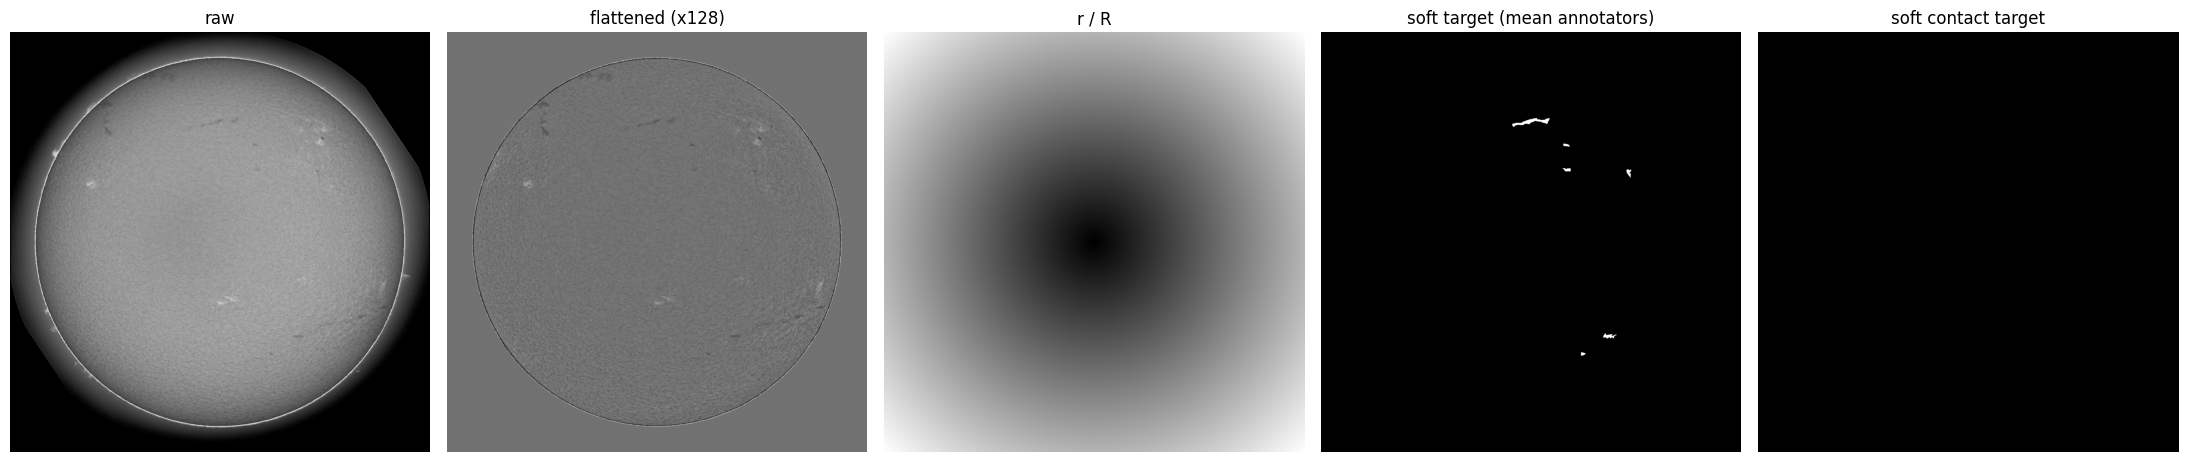

In [7]:
CY, CX = (H - 1) / 2.0, (W - 1) / 2.0
DISK_R = CFG.disk_radius_fraction * min(H, W) / 2.0
_YY, _XX = np.mgrid[0:H, 0:W]
RADIAL = (np.hypot(_YY - CY, _XX - CX) / DISK_R).astype(np.float32)
YY_FLAT = _YY.ravel().astype(np.float64)
XX_FLAT = _XX.ravel().astype(np.float64)
del _YY, _XX
DISK = RADIAL < 1.0
RBIN = np.minimum((RADIAL * CFG.radial_bins).astype(np.int32), CFG.radial_bins - 1)
RBIN_DISK = RBIN[DISK]

IMG_MEAN, IMG_STD = 0.5, 0.25
RAD_MEAN, RAD_STD, RAD_CLIP = 0.6, 0.35, 1.25

def flatten_disk(img):
    """Divide by the radial limb-darkening profile, then by a large local median; off-disk = neutral (1.0 -> 128)."""
    x = img.astype(np.float32)
    nb = CFG.radial_bins
    s = np.bincount(RBIN_DISK, weights=x[DISK], minlength=nb)
    c = np.bincount(RBIN_DISK, minlength=nb)
    valid = c > 0
    prof = np.interp(np.arange(nb), np.flatnonzero(valid), (s[valid] / c[valid]))
    k = 7
    prof = np.convolve(np.pad(prof, k // 2, mode="edge"), np.ones(k) / k, mode="valid")
    ratio = x / np.maximum(prof[RBIN], 1.0).astype(np.float32)
    ratio[~DISK] = 1.0
    small = cv2.resize(ratio, (W // 4, H // 4), interpolation=cv2.INTER_AREA)
    small_u8 = np.clip(small * 128.0, 0, 255).astype(np.uint8)
    ksize = max(3, int(round(CFG.flat_median_kernel * H / 2048)) | 1)
    med = cv2.medianBlur(small_u8, ksize).astype(np.float32) / 128.0
    med = cv2.resize(med, (W, H), interpolation=cv2.INTER_LINEAR)
    flat = ratio / np.maximum(med, 0.25)
    flat[~DISK] = 1.0
    return np.clip(flat * 128.0, 0, 255).astype(np.uint8)

CACHE = LOCAL_ROOT / "cache" / f"v3_{ANN_SHA[:12]}_{H}x{W}_r{CFG.disk_radius_fraction:.4f}_k{CFG.flat_median_kernel}_c{CFG.contact_radius}"
for sub in ("img", "flat", "soft", "contact", "gt"):
    (CACHE / sub).mkdir(parents=True, exist_ok=True)

def cache_key(split, name):
    return f"{split}__{Path(name).stem}"

def cache_image(split, name, path):
    key = cache_key(split, name)
    ip, fp = CACHE / "img" / f"{key}.npy", CACHE / "flat" / f"{key}.npy"
    if ip.is_file() and fp.is_file():
        return
    img = read_gray(path)
    if img.shape != (H, W):
        raise ValueError(f"Wrong JPEG shape {img.shape}: {path}")
    save_npy_atomic(ip, img)
    save_npy_atomic(fp, flatten_disk(img))

def build_targets(name):
    key = cache_key("train", name)
    gp = CACHE / "gt" / f"{key}.pkl"
    sp, cp = CACHE / "soft" / f"{key}.npy", CACHE / "contact" / f"{key}.npy"
    if gp.is_file() and sp.is_file() and cp.is_file():
        with open(gp, "rb") as f:
            return pickle.load(f)
    r = CFG.contact_radius
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))
    rng = np.random.default_rng(int(hashlib.sha256(name.encode()).hexdigest()[:8], 16))
    soft = np.zeros((H, W), np.float32)
    contact = np.zeros((H, W), np.float32)
    records, points = [], []
    for rid in RECORD_IDS_BY_FILE[name]:
        union = np.zeros((H, W), bool)
        count = np.zeros((H, W), np.uint8)
        idx_list, areas = [], []
        for ann in ANNOTATIONS_BY_ID[rid]:
            m = decode_mask(segmentation_to_rle(ann["segmentation"], H, W))
            if not m.any():
                raise ValueError(f"Empty filament annotation {ann['id']}")
            flat_idx = np.flatnonzero(m).astype(np.int32)
            idx_list.append(flat_idx); areas.append(len(flat_idx))
            union |= m
            ys, xs = flat_idx // W, flat_idx % W
            y0, y1 = max(int(ys.min()) - r, 0), min(int(ys.max()) + r + 1, H)
            x0, x1 = max(int(xs.min()) - r, 0), min(int(xs.max()) + r + 1, W)
            count[y0:y1, x0:x1] += cv2.dilate(m[y0:y1, x0:x1].astype(np.uint8), kernel)
            take = rng.choice(len(flat_idx), size=min(32, len(flat_idx)), replace=False)
            points.append(np.stack([ys[take], xs[take]], 1).astype(np.int32))
        soft += union
        contact += (count >= 2)
        records.append({"id": rid, "idx": idx_list, "area": np.asarray(areas, np.float64)})
    n = max(len(records), 1)
    save_npy_atomic(sp, np.rint(soft / n * 255).astype(np.uint8))
    save_npy_atomic(cp, np.rint(contact / n * 255).astype(np.uint8))
    gt = {"name": name, "records": records, "points": points}
    with open(gp.with_suffix(".tmp"), "wb") as f:
        pickle.dump(gt, f, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(gp.with_suffix(".tmp"), gp)
    return gt

with ThreadPoolExecutor(max_workers=min(8, CPU_COUNT)) as pool:
    list(tqdm(pool.map(lambda n: cache_image("train", n, TRAIN_PATHS[n]), UNIQUE_FILES),
              total=len(UNIQUE_FILES), desc="Cache train images + flattened"))
    list(tqdm(pool.map(lambda n: cache_image("test", n, TEST_PATHS[n]), sorted(TEST_PATHS)),
              total=len(TEST_PATHS), desc="Cache test images + flattened"))
    GT_LIST = list(tqdm(pool.map(build_targets, UNIQUE_FILES), total=len(UNIQUE_FILES),
                        desc="Soft/contact targets + GT index"))
GT_INDEX = {g["name"]: g for g in GT_LIST}
del GT_LIST

@lru_cache(maxsize=64)
def cached_arrays(key, with_targets=True):
    subs = ("img", "flat", "soft", "contact") if with_targets else ("img", "flat")
    return tuple(np.load(CACHE / s / f"{key}.npy", mmap_mode="r") for s in subs)

# Sanity: disk radius estimate from a few images (off-disk sky is ~0)
_est = []
for n in UNIQUE_FILES[:: max(1, len(UNIQUE_FILES) // 12)]:
    im = np.asarray(cached_arrays(cache_key("train", n))[0])
    _est.append(math.sqrt((im > 12).sum() / math.pi))
print(f"Configured disk radius {DISK_R:.1f}px | estimated from images (incl. halo) median {np.median(_est):.1f}px")
print("Mean instances per record:", round(np.mean([len(r['idx']) for g in GT_INDEX.values() for r in g['records']]), 2))

_ex = UNIQUE_FILES[0]
_i, _f, _s, _c = cached_arrays(cache_key("train", _ex))
fig, ax = plt.subplots(1, 5, figsize=(22, 4.5))
for a, arr, t in zip(ax, (_i, _f, RADIAL, _s, _c), ("raw", "flattened (x128)", "r / R", "soft target (mean annotators)", "soft contact target")):
    a.imshow(np.asarray(arr), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

## Cell 07 — 4-fold grouped split (same capture date or identical bytes never cross folds), frozen on Drive

In [8]:
def capture_groups(names):
    parent = {n: n for n in names}
    def find(n):
        while parent[n] != n:
            parent[n] = parent[parent[n]]
            n = parent[n]
        return n
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    by_date, by_hash = {}, {}
    for n in names:
        if CFG.group_by_date:
            m = re.match(r"^(\d{8})\d{6}[A-Za-z]{2}$", Path(n).stem)
            if not m:
                raise ValueError(f"Filename date parsing failed: {n}")
            d = m.group(1)
            if d in by_date: union(n, by_date[d])
            by_date[d] = n
        h = FILE_HASHES[n]
        if h in by_hash: union(n, by_hash[h])
        by_hash[h] = n
    return {n: find(n) for n in names}

FOLDS_PATH = RUN / "folds_v3.csv"
if FOLDS_PATH.exists():
    FOLDS = pd.read_csv(FOLDS_PATH, dtype={"file_name": str, "group": str, "v1_split": str})
    if set(FOLDS.file_name) != set(UNIQUE_FILES):
        raise ValueError("Frozen folds_v3.csv does not match the dataset. Use a new run folder.")
    print("Reusing frozen folds:", FOLDS_PATH)
else:
    groups = capture_groups(UNIQUE_FILES)
    members = defaultdict(list)
    for n, g in groups.items():
        members[g].append(n)
    rng = np.random.default_rng(CFG.seed)
    gkeys = sorted(members)
    tiebreak = dict(zip(gkeys, rng.permutation(len(gkeys))))
    counts = np.zeros(CFG.n_folds, int)
    fold_of = {}
    for g in sorted(gkeys, key=lambda g: (-len(members[g]), tiebreak[g])):
        f = int(np.argmin(counts))
        for n in members[g]:
            fold_of[n] = f
        counts[f] += len(members[g])
    v1 = {}
    if V1_SPLIT_CSV.is_file():
        _v1 = pd.read_csv(V1_SPLIT_CSV, dtype=str)
        v1 = {canonical_filename(a): b for a, b in zip(_v1.file_name, _v1.split)}
    FOLDS = pd.DataFrame([{"file_name": n, "fold": fold_of[n], "group": groups[n],
                           "v1_split": v1.get(n, "")} for n in UNIQUE_FILES])
    FOLDS.to_csv(FOLDS_PATH, index=False)
FOLDS["fold"] = FOLDS["fold"].astype(int)
FOLDS["v1_split"] = FOLDS["v1_split"].fillna("")
if FOLDS.groupby("group").fold.nunique().max() > 1:
    raise ValueError("Leakage: a capture-date/hash group spans folds")
FOLD_OF = dict(zip(FOLDS.file_name, FOLDS.fold))
FOLDS_SHA = object_hash(FOLDS[["file_name", "fold"]].sort_values("file_name").values.tolist())
print(FOLDS.groupby("fold").agg(jpegs=("file_name", "size")).assign(
    records=FOLDS.groupby("fold").file_name.apply(lambda s: sum(len(RECORD_IDS_BY_FILE[n]) for n in s))))
print("Folds hash:", FOLDS_SHA[:16], "| V1 split available for comparison:", bool((FOLDS.v1_split != "").any()))

Reusing frozen folds: /content/drive/MyDrive/SFSC2026/outputs/sfsc_unet_v3/folds_v3.csv
      jpegs  records
fold                
0       177      288
1       177      291
2       177      292
3       176      283
Folds hash: c646810700142973 | V1 split available for comparison: True


## Cell 08 — Exact PQ engine and instance extraction (shared by training eval, calibration, diagnostics and test export)
All post-processing runs on **uint8** probability maps (p = u8/255) so calibration and test use bit-identical thresholds.

*Geometry* = (t_low, contact threshold or None, boundary offset px) decides the masks. *Filters* = (t_high seed, min mean prob,
min area) decide which masks are kept. Hysteresis = keep a low-threshold component only if its max probability reaches t_high.

In [9]:
STRUCT8 = ndi.generate_binary_structure(2, 2)
STRUCT4 = ndi.generate_binary_structure(2, 1)
CONN = STRUCT8 if CFG.connectivity == 8 else STRUCT4
FEATURES = ("log_area", "mean_p", "max_p", "frac50", "frac70", "frac90", "mean_contact",
            "elongation", "major_len", "radial", "mean_img", "mean_flat")
F_IDX = {k: i for i, k in enumerate(FEATURES)}

def qt(t):
    return int(round(float(t) * 255))

def match_stats(iou):
    """Strict IoU>0.5, one-to-one max-IoU assignment. Returns (sum_iou, tp, fp, fn, records)."""
    n_gt, n_pred = iou.shape
    if n_gt == 0 or n_pred == 0:
        return np.array([0.0, 0, n_pred, n_gt, 1], np.float64)
    q = iou > 0.5
    if not q.any():
        return np.array([0.0, 0, n_pred, n_gt, 1], np.float64)
    rows, cols = np.flatnonzero(q.any(1)), np.flatnonzero(q.any(0))
    sub = np.where(q[np.ix_(rows, cols)], iou[np.ix_(rows, cols)], 0.0)
    r, c = linear_sum_assignment(sub, maximize=True)
    v = sub[r, c]
    v = v[v > 0]
    tp = len(v)
    return np.array([float(v.sum()), tp, n_pred - tp, n_gt - tp, 1], np.float64)

def match_pairs(iou):
    if iou.size == 0 or not (iou > 0.5).any():
        return []
    sub = np.where(iou > 0.5, iou, 0.0)
    r, c = linear_sum_assignment(sub, maximize=True)
    return [(int(a), int(b), float(sub[a, b])) for a, b in zip(r, c) if sub[a, b] > 0]

def summarize(st):
    s, tp, fp, fn, rec = [float(x) for x in st]
    den = tp + 0.5 * (fp + fn)
    return {"pq": s / den if den else 1.0, "sq": s / tp if tp else 0.0, "rq": tp / den if den else 1.0,
            "precision": tp / (tp + fp) if tp + fp else 0.0, "recall": tp / (tp + fn) if tp + fn else 0.0,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "records": int(rec)}

def relabel(lab):
    if lab.max() == 0:
        return np.zeros(lab.shape, np.int32), 0
    areas = np.bincount(lab.ravel())
    ids = np.flatnonzero(areas[1:]) + 1
    lut = np.zeros(len(areas), np.int32)
    lut[ids] = np.arange(1, len(ids) + 1, dtype=np.int32)
    return lut[lab], len(ids)

def fill_label_holes(lab):
    fg = lab > 0
    holes = ndi.binary_fill_holes(fg) & ~fg
    if not holes.any():
        return lab
    hl, _ = ndi.label(holes, structure=STRUCT4)
    out = lab.copy()
    for i, sl in enumerate(ndi.find_objects(hl), 1):
        if sl is None:
            continue
        esl = (slice(max(sl[0].start - 1, 0), sl[0].stop + 1), slice(max(sl[1].start - 1, 0), sl[1].stop + 1))
        hole = hl[esl] == i
        ring = ndi.binary_dilation(hole, STRUCT8) & ~hole
        vals = lab[esl][ring]
        vals = vals[vals > 0]
        if vals.size:
            out[esl][hole] = np.bincount(vals).argmax()
    return out

def geometry_labels(fg, ct, geom):
    t_low, contact_t, offset = geom
    low = fg >= qt(t_low)
    if contact_t is not None:
        cores = low & (ct < qt(contact_t))
        lab, n = ndi.label(cores, structure=CONN)
        if n:
            areas = np.bincount(lab.ravel(), minlength=n + 1)
            small = areas < CFG.min_core_area
            small[0] = False
            if small.any():
                lab[small[lab]] = 0
        if lab.any():
            dist, (iy, ix) = ndi.distance_transform_edt(lab == 0, return_distances=True, return_indices=True)
            lab = np.where(low & (dist <= CFG.contact_assign_radius), lab[iy, ix], 0).astype(np.int32)
        else:
            lab = np.zeros((fg.shape), np.int32)
    else:
        lab, _ = ndi.label(low, structure=CONN)
        lab = lab.astype(np.int32)
    if CFG.fill_holes and lab.any():
        lab = fill_label_holes(lab)
    for _ in range(max(offset, 0)):
        lab = np.where(lab == 0, ndi.grey_dilation(lab, footprint=STRUCT4), lab)
    for _ in range(max(-offset, 0)):
        lab = np.where(ndi.grey_erosion(lab, footprint=STRUCT4) == lab, lab, 0)
    return relabel(lab)

def component_features(lab, n, fg, ct, img, flat):
    if n == 0:
        return np.zeros((0, len(FEATURES)), np.float32), np.zeros(0, np.float64)
    L = lab.ravel()
    nz = np.flatnonzero(L)
    Lz = L[nz]
    def s(w):
        return np.bincount(Lz, weights=w, minlength=n + 1)[1:]
    area = np.bincount(Lz, minlength=n + 1)[1:].astype(np.float64)
    a = np.maximum(area, 1.0)
    fgz = np.asarray(fg).ravel()[nz]
    p = fgz.astype(np.float64) / 255.0
    mx = np.zeros(n + 1, np.float64)
    np.maximum.at(mx, Lz, fgz.astype(np.float64))
    yz, xz = YY_FLAT[nz], XX_FLAT[nz]
    my, mxx = s(yz) / a, s(xz) / a
    syy = np.maximum(s(yz * yz) / a - my ** 2, 0)
    sxx = np.maximum(s(xz * xz) / a - mxx ** 2, 0)
    sxy = s(yz * xz) / a - my * mxx
    tr, det = syy + sxx, syy * sxx - sxy ** 2
    disc = np.sqrt(np.maximum(tr ** 2 / 4 - det, 0))
    l1, l2 = tr / 2 + disc, np.maximum(tr / 2 - disc, 1e-3)
    feats = np.stack([
        np.log1p(area), s(p) / a, mx[1:] / 255.0,
        s((fgz >= qt(0.5)).astype(np.float64)) / a, s((fgz >= qt(0.7)).astype(np.float64)) / a,
        s((fgz >= qt(0.9)).astype(np.float64)) / a,
        s(np.asarray(ct).ravel()[nz].astype(np.float64) / 255.0) / a,
        np.sqrt((l1 + 1e-3) / l2), 4.0 * np.sqrt(l1),
        np.hypot(my - CY, mxx - CX) / DISK_R,
        s(np.asarray(img).ravel()[nz].astype(np.float64) / 255.0) / a,
        s(np.asarray(flat).ravel()[nz].astype(np.float64) / 128.0) / a,
    ], 1).astype(np.float32)
    return feats, area

def overlap_matrices(lab, n, area, gt):
    L = lab.ravel()
    out = []
    for rec in gt["records"]:
        inter = np.zeros((len(rec["idx"]), n), np.float64)
        if n:
            for j, idx in enumerate(rec["idx"]):
                inter[j] = np.bincount(L[idx], minlength=n + 1)[1:]
        union = rec["area"][:, None] + area[None, :] - inter
        iou = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
        out.append((inter, iou))
    return out

def grid_keep(feats, area, flt):
    th, mc, ma = flt
    if len(area) == 0:
        return np.zeros(0, bool)
    return ((np.rint(feats[:, F_IDX["max_p"]] * 255) >= qt(th)) & (feats[:, F_IDX["mean_p"]] >= mc - 1e-9)
            & (area >= ma))

def prefilter_keep(feats, area):
    if len(area) == 0:
        return np.zeros(0, bool)
    return ((np.rint(feats[:, F_IDX["max_p"]] * 255) >= qt(CFG.scorer_prefilter_max))
            & (area >= CFG.scorer_prefilter_area))

def load_maps(fg, ct):
    if isinstance(fg, (str, Path)):
        fg = np.load(fg, mmap_mode="r")
    if isinstance(ct, (str, Path)):
        ct = np.load(ct, mmap_mode="r")
    return np.asarray(fg), np.asarray(ct)

# ---- process-pool workers (fork: they see GT_INDEX, CACHE, CFG of the parent at fork time) ----
def score_image_grid(task):
    name, fg, ct, geoms, filters = task
    fg, ct = load_maps(fg, ct)
    img, flat = cached_arrays(cache_key("train", name), False)
    gt = GT_INDEX[name]
    out = np.zeros((len(geoms), len(filters), 5), np.float64)
    for gi, g in enumerate(geoms):
        lab, n = geometry_labels(fg, ct, g)
        feats, area = component_features(lab, n, fg, ct, img, flat)
        mats = overlap_matrices(lab, n, area, gt)
        for fi, flt in enumerate(filters):
            keep = grid_keep(feats, area, flt)
            for _, iou in mats:
                out[gi, fi] += match_stats(iou[:, keep])
    return name, out

def scorer_rows(task):
    name, fg, ct, geom = task
    fg, ct = load_maps(fg, ct)
    img, flat = cached_arrays(cache_key("train", name), False)
    lab, n = geometry_labels(fg, ct, geom)
    feats, area = component_features(lab, n, fg, ct, img, flat)
    mats = overlap_matrices(lab, n, area, GT_INDEX[name])
    y = np.zeros(n, np.float64)
    for _, iou in mats:
        if iou.shape[0] and n:
            b = iou.max(0)
            y += np.where(b > 0.5, b, 0.0)
    y /= max(len(mats), 1)
    pre = prefilter_keep(feats, area)
    return name, feats[pre], area[pre], y[pre], [iou[:, pre] for _, iou in mats]

_POOL = None
def get_pool(refresh=False):
    """Fork-based CPU pool. Refresh after defining new globals that workers must see."""
    global _POOL
    if refresh and _POOL is not None:
        _POOL.shutdown(wait=True)
        _POOL = None
    if _POOL is None:
        _POOL = ProcessPoolExecutor(max_workers=CPU_POOL, mp_context=mp.get_context("fork"))
    return _POOL

def stats_table(total, geoms, filters):
    rows = []
    for gi, g in enumerate(geoms):
        for fi, f in enumerate(filters):
            rows.append({"t_low": g[0], "contact": g[1], "offset": g[2], "t_high": f[0], "min_mean": f[1],
                         "min_area": f[2], **summarize(total[gi, fi])})
    return pd.DataFrame(rows)

def pick_best(table):
    t = table.copy()
    t["_c"] = t["contact"].isna()
    t["_o"] = (t["offset"] == 0)
    t = t.sort_values(["pq", "_c", "_o", "min_area", "min_mean"], ascending=[False, False, False, True, True])
    return t.iloc[0].drop(["_c", "_o"]).to_dict()

def as_geom(row):
    c = row["contact"]
    return (float(row["t_low"]), None if (c is None or (isinstance(c, float) and np.isnan(c))) else float(c), int(row["offset"]))

def as_filter(row):
    return (float(row["t_high"]), float(row["min_mean"]), int(row["min_area"]))

print("PQ engine ready. Features:", FEATURES)

PQ engine ready. Features: ('log_area', 'mean_p', 'max_p', 'frac50', 'frac70', 'frac90', 'mean_contact', 'elongation', 'major_len', 'radial', 'mean_img', 'mean_flat')


## Cell 09 — Label diagnostics: oracle ceilings (no model involved)
* **CC-of-GT oracle**: connected components of one annotator's own union mask scored against that annotator's instances.
  This is the best PQ a pure threshold->connected-components pipeline could ever reach (touching filaments merge).
* **Inter-annotator PQ**: annotator A's instances scored as predictions against annotator B (all ordered pairs).
  This is a practical human-agreement ceiling for the per-record scoring.

In [10]:
def oracle_task(name):
    gt = GT_INDEX[name]
    cc_total = np.zeros(5)
    for rec in gt["records"]:
        union = np.zeros(H * W, bool)
        for idx in rec["idx"]:
            union[idx] = True
        lab, n = ndi.label(union.reshape(H, W), structure=CONN)
        lab = lab.astype(np.int32)
        area = np.bincount(lab.ravel(), minlength=n + 1)[1:].astype(np.float64)
        (_, iou), = overlap_matrices(lab, n, area, {"records": [rec]})
        cc_total += match_stats(iou)
    ia_total = np.zeros(5)
    recs = gt["records"]
    for a in range(len(recs)):
        for b in range(len(recs)):
            if a == b:
                continue
            A, B = recs[a], recs[b]
            iou = np.zeros((len(B["idx"]), len(A["idx"])))
            for i, gi in enumerate(B["idx"]):
                for j, pj in enumerate(A["idx"]):
                    inter = np.intersect1d(gi, pj, assume_unique=True).size
                    if inter:
                        iou[i, j] = inter / (len(gi) + len(pj) - inter)
            ia_total += match_stats(iou)
    return name, cc_total, ia_total

ORACLE_PATH = RUN / "label_oracles_v3.json"
if ORACLE_PATH.exists():
    ORACLES = json.loads(ORACLE_PATH.read_text())
else:
    pool = get_pool(refresh=True)
    cc_all, ia_all = np.zeros(5), np.zeros(5)
    for name, cc, ia in tqdm(pool.map(oracle_task, UNIQUE_FILES, chunksize=4), total=len(UNIQUE_FILES),
                             desc="Label oracles"):
        cc_all += cc; ia_all += ia
    ORACLES = {"cc_of_gt": summarize(cc_all), "inter_annotator": summarize(ia_all) if ia_all[4] else None}
    write_json(ORACLE_PATH, ORACLES)
print("CC-of-GT oracle (ceiling of threshold+CC):", {k: round(v, 4) if isinstance(v, float) else v
                                                    for k, v in ORACLES["cc_of_gt"].items()})
if ORACLES["inter_annotator"]:
    print("Inter-annotator PQ (human agreement):     ", {k: round(v, 4) if isinstance(v, float) else v
                                                        for k, v in ORACLES["inter_annotator"].items()})

CC-of-GT oracle (ceiling of threshold+CC): {'pq': 0.9972, 'sq': 0.9996, 'rq': 0.9976, 'precision': 0.9963, 'recall': 0.9988, 'tp': 8189, 'fp': 30, 'fn': 10, 'records': 1154}
Inter-annotator PQ (human agreement):      {'pq': 0.3397, 'sq': 0.6336, 'rq': 0.5361, 'precision': 0.5361, 'recall': 0.5361, 'tp': 4288, 'fp': 3711, 'fn': 3711, 'records': 1196}


## Cell 10 — Hard-negative centres: dark (in the flattened image), on-disk, far from ANY annotator's filament

In [11]:
def hard_negative_points(name, grid=8, max_points=512):
    _, flat, soft, _ = cached_arrays(cache_key("train", name))
    gh, gw = H // grid, W // grid
    coarse_gt = (np.asarray(soft)[: gh * grid, : gw * grid] > 0).reshape(gh, grid, gw, grid).max(axis=(1, 3))
    excluded = cv2.dilate(coarse_gt.astype(np.uint8), np.ones((9, 9), np.uint8)) > 0
    coarse_flat = cv2.resize(np.asarray(flat), (gw, gh), interpolation=cv2.INTER_AREA).astype(np.float32)
    coarse_r = RADIAL[grid // 2:: grid, grid // 2:: grid][:gh, :gw]
    valid = (~excluded) & (coarse_r < 0.98)
    if not valid.any():
        return np.zeros((0, 2), np.int32)
    darkness = 128.0 - coarse_flat
    thr = np.percentile(darkness[valid], 85)
    cand = np.flatnonzero(valid & (darkness >= thr))
    if not len(cand):
        cand = np.flatnonzero(valid)
    rng = np.random.default_rng(int(hashlib.sha256(name.encode()).hexdigest()[:8], 16))
    take = rng.choice(cand, size=min(max_points, len(cand)), replace=False)
    return np.stack([(take // gw) * grid + grid // 2, (take % gw) * grid + grid // 2], 1).astype(np.int32)

with ThreadPoolExecutor(max_workers=min(8, CPU_COUNT)) as pool:
    HARD_POINTS = dict(zip(UNIQUE_FILES, tqdm(pool.map(hard_negative_points, UNIQUE_FILES),
                                              total=len(UNIQUE_FILES), desc="Hard-negative centres")))
print("Mean hard-negative centres per JPEG:", round(np.mean([len(v) for v in HARD_POINTS.values()]), 1))

Hard-negative centres:   0%|          | 0/707 [00:00<?, ?it/s]

Mean hard-negative centres per JPEG: 512.0


## Cell 11 — Training crops: 3-channel input, soft targets, free rotation / scale, D4, photometric augmentation

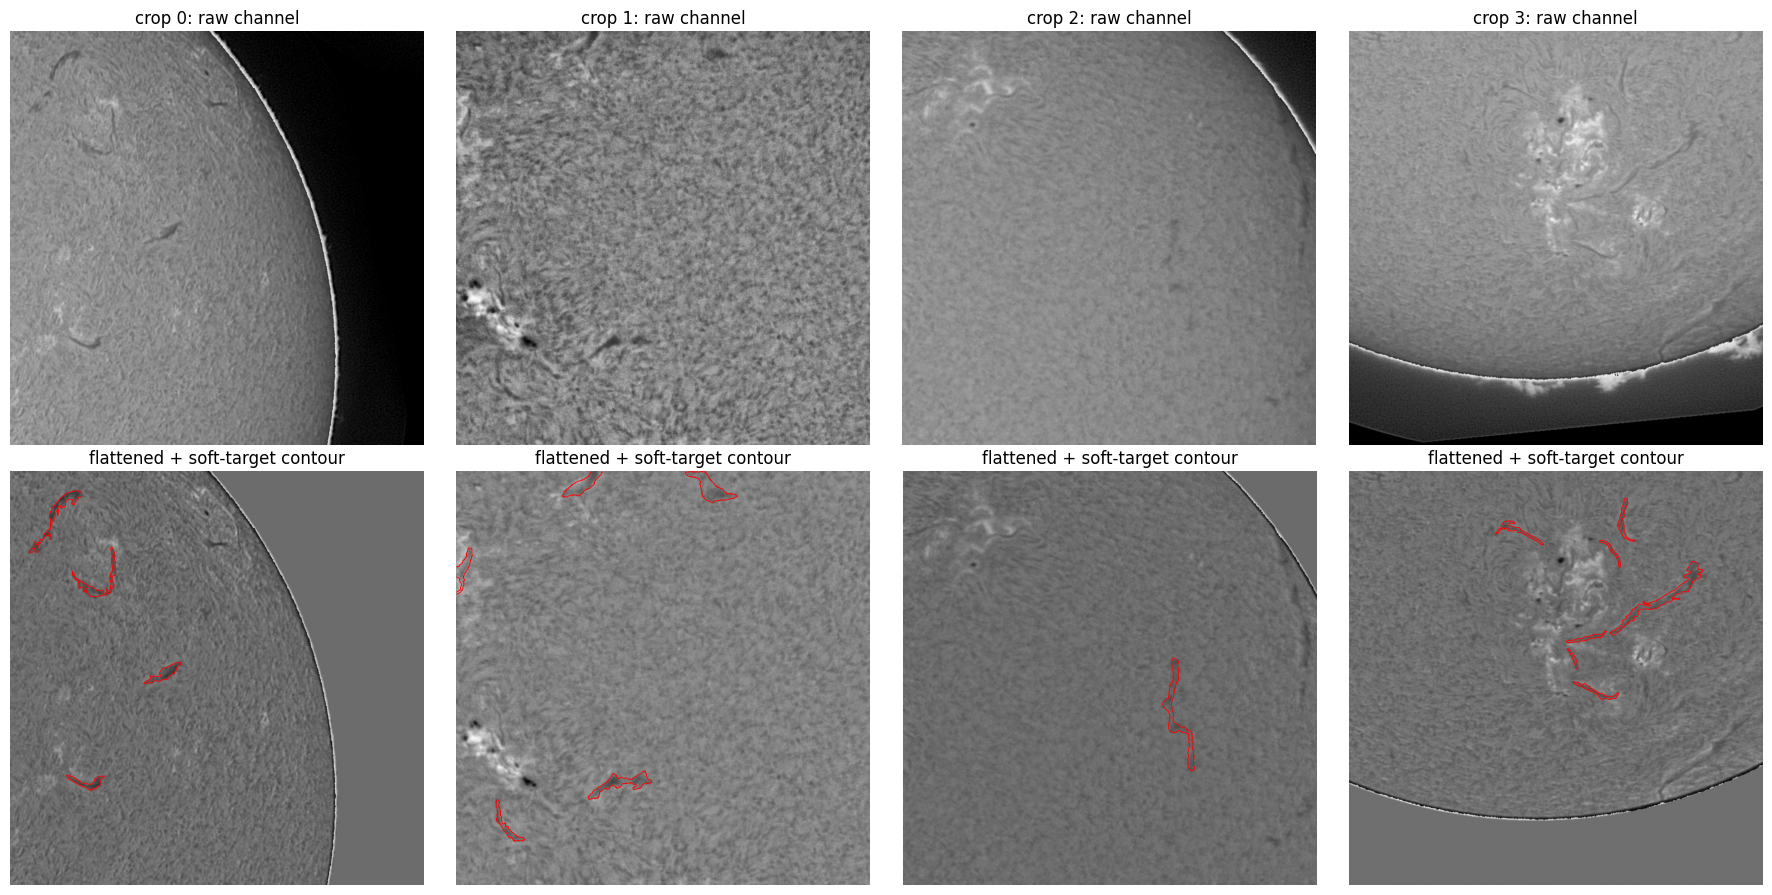

Crop tensors: (3, 768, 768) torch.float32 | targets: (2, 768, 768) torch.uint8


In [12]:
def normalize_np(img01, flat_ratio, radial):
    return np.stack([(img01 - IMG_MEAN) / IMG_STD,
                     (flat_ratio - 1.0) / CFG.flat_std,
                     (np.clip(radial, 0, RAD_CLIP) - RAD_MEAN) / RAD_STD]).astype(np.float32)

class CropDatasetV3(Dataset):
    def __init__(self, names, length, fold, cfg):
        self.names = sorted(names)
        self.length, self.fold, self.cfg = int(length), int(fold), cfg
        self.shared_epoch = mp.Value("q", 0)

    def set_epoch(self, epoch):
        self.shared_epoch.value = int(epoch)

    def __len__(self):
        return self.length

    def __getitem__(self, index):
        c = self.cfg
        rng = np.random.default_rng([c.seed, self.fold, int(self.shared_epoch.value), int(index)])
        name = self.names[int(rng.integers(len(self.names)))]
        img, flat, soft, contact = cached_arrays(cache_key("train", name))
        S = c.crop_size
        draw = rng.random()
        pts, hard = GT_INDEX[name]["points"], HARD_POINTS.get(name)
        if draw < c.p_positive and pts:
            inst = pts[int(rng.integers(len(pts)))]
            cy, cx = inst[int(rng.integers(len(inst)))]
            cy, cx = cy + rng.integers(-S // 4, S // 4 + 1), cx + rng.integers(-S // 4, S // 4 + 1)
        elif draw < c.p_positive + c.p_hard_negative and hard is not None and len(hard):
            cy, cx = hard[int(rng.integers(len(hard)))]
            cy, cx = cy + rng.integers(-S // 8, S // 8 + 1), cx + rng.integers(-S // 8, S // 8 + 1)
        else:
            cy, cx = rng.integers(H), rng.integers(W)
        angle = float(rng.uniform(0, 360)) if rng.random() < c.p_free_rotation else 0.0
        scale = float(rng.uniform(*c.scale_range)) if rng.random() < c.p_scale else 1.0
        sources = (img, flat, RADIAL, soft, contact)
        if angle == 0.0 and scale == 1.0:
            y0 = int(np.clip(cy - S // 2, 0, H - S)); x0 = int(np.clip(cx - S // 2, 0, W - S))
            crop = [np.asarray(a[y0:y0 + S, x0:x0 + S], dtype=np.float32) for a in sources]
        else:
            cy = float(np.clip(cy, S / 2, H - S / 2)); cx = float(np.clip(cx, S / 2, W - S / 2))
            half = int(math.ceil(S / 2 / scale * 1.4143)) + 2
            ya, yb = max(int(cy) - half, 0), min(int(cy) + half + 1, H)
            xa, xb = max(int(cx) - half, 0), min(int(cx) + half + 1, W)
            th = math.radians(angle)
            cs, sn = math.cos(th) / scale, math.sin(th) / scale
            d = (S - 1) / 2.0
            lcy, lcx = cy - ya, cx - xa
            M = np.array([[cs, -sn, lcx - cs * d + sn * d],
                          [sn, cs, lcy - sn * d - cs * d]], np.float64)
            crop = [cv2.warpAffine(np.ascontiguousarray(a[ya:yb, xa:xb], dtype=np.float32), M, (S, S),
                                   flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP,
                                   borderMode=cv2.BORDER_REFLECT_101) for a in sources]
        k, flip = int(rng.integers(4)), rng.random() < 0.5
        crop = [np.rot90(a[:, ::-1] if flip else a, k) for a in crop]
        im = crop[0]
        if rng.random() < c.p_clahe:
            im = cv2.createCLAHE(clipLimit=float(rng.uniform(1.2, 2.0)), tileGridSize=(8, 8)).apply(
                np.ascontiguousarray(np.clip(im, 0, 255).astype(np.uint8))).astype(np.float32)
        im = np.ascontiguousarray(im, dtype=np.float32) / 255.0
        if rng.random() < c.p_blur:
            im = cv2.GaussianBlur(im, (3, 3), float(rng.uniform(0.4, 0.8)))
        if rng.random() < c.p_gamma:
            im = np.power(np.clip(im, 1e-6, 1.0), float(rng.uniform(*c.gamma_range)))
        if rng.random() < c.p_brightness_contrast:
            im = (im - 0.5) * rng.uniform(1 - c.contrast, 1 + c.contrast) + 0.5 + rng.uniform(-c.brightness, c.brightness)
        if rng.random() < c.p_noise:
            im = im + rng.normal(0, c.noise_std, im.shape).astype(np.float32)
        im = np.clip(im, 0, 1)
        fl = crop[1] / 128.0
        if rng.random() < c.p_flat_jitter:
            fl = 1.0 + (fl - 1.0) * rng.uniform(0.85, 1.15)
        x = normalize_np(im, fl, crop[2])
        y = np.stack([np.clip(np.rint(crop[3]), 0, 255), np.clip(np.rint(crop[4]), 0, 255)]).astype(np.uint8)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

def init_loader_worker(_):
    cv2.setNumThreads(1)
    torch.set_num_threads(1)

def make_loader(dataset, micro):
    args = dict(batch_size=micro, shuffle=False, drop_last=True, num_workers=WORKERS, pin_memory=True,
                worker_init_fn=init_loader_worker)
    if WORKERS:
        args.update(persistent_workers=True, prefetch_factor=CFG.prefetch_factor)
    return DataLoader(dataset, **args)

_preview = CropDatasetV3(UNIQUE_FILES, 8, 0, CFG)
fig, ax = plt.subplots(2, 4, figsize=(18, 9))
for i in range(4):
    xb, yb = _preview[i]
    ax[0, i].imshow(xb[0], cmap="gray"); ax[0, i].set_title(f"crop {i}: raw channel"); ax[0, i].axis("off")
    ax[1, i].imshow(xb[1], cmap="gray"); ax[1, i].contour(yb[0].numpy() >= 128, levels=[0.5], colors="r", linewidths=0.6)
    ax[1, i].set_title("flattened + soft-target contour"); ax[1, i].axis("off")
plt.tight_layout(); plt.show()
print("Crop tensors:", tuple(xb.shape), xb.dtype, "| targets:", tuple(yb.shape), yb.dtype)

## Cell 12 — Model: UNet with EfficientNetV2-S encoder (stride-2 skip + full-resolution decoder), scSE, 2 outputs (filament, contact)

In [13]:
def build_model(encoder, pretrained):
    Arch = getattr(smp, CFG.architecture)
    kwargs = dict(encoder_name=encoder, encoder_weights=("imagenet" if pretrained else None),
                  in_channels=3, classes=2)
    if CFG.architecture in ("Unet", "UnetPlusPlus") and CFG.decoder_attention:
        kwargs["decoder_attention_type"] = CFG.decoder_attention
    model = Arch(**kwargs)
    head = model.segmentation_head[0]
    if isinstance(head, nn.Conv2d) and head.bias is not None:
        with torch.no_grad():
            head.bias.copy_(torch.tensor([math.log(0.03 / 0.97), math.log(0.003 / 0.997)]))
    return model

def to_device(model):
    model = model.to(DEVICE)
    return model.to(memory_format=torch.channels_last) if CFG.channels_last else model

ENCODER_PATH = RUN / "resolved_encoder.json"
if ENCODER_PATH.exists():
    RESOLVED_ENCODER = json.loads(ENCODER_PATH.read_text())["encoder"]
else:
    RESOLVED_ENCODER, _errors = None, []
    for cand in (CFG.encoder_name,) + tuple(CFG.encoder_fallbacks):
        try:
            _m = build_model(cand, pretrained=True)
            RESOLVED_ENCODER = cand
            del _m
            break
        except Exception as exc:
            _errors.append(f"{cand}: {type(exc).__name__}: {str(exc)[:200]}")
    if RESOLVED_ENCODER is None:
        raise RuntimeError("No encoder could be built with pretrained weights:\n" + "\n".join(_errors))
    if _errors:
        print("Encoder fallbacks used:\n" + "\n".join(_errors))
    write_json(ENCODER_PATH, {"encoder": RESOLVED_ENCODER})
_m = build_model(RESOLVED_ENCODER, pretrained=False)
print(f"{CFG.architecture} / {RESOLVED_ENCODER} | parameters: {sum(p.numel() for p in _m.parameters())/1e6:.1f} M")
del _m

Unet / tu-tf_efficientnetv2_s.in21k_ft_in1k | parameters: 22.1 M


## Cell 13 — Loss: 0.5·BCE(soft) + 1.0·Lovász hinge + 0.2·edge BCE + 0.5·contact BCE (+ optional clDice)

In [14]:
def lovasz_grad(gt_sorted):
    gts = gt_sorted.sum()
    intersection = gts - gt_sorted.cumsum(0)
    union = gts + (1.0 - gt_sorted).cumsum(0)
    jaccard = 1.0 - intersection / union
    if gt_sorted.numel() > 1:
        jaccard[1:] = jaccard[1:] - jaccard[:-1]
    return jaccard

def lovasz_hinge_flat(logits, labels):
    """Berman et al. 2018: convex surrogate of the Jaccard (IoU) loss, computed over the whole micro-batch."""
    signs = 2.0 * labels - 1.0
    errors = 1.0 - logits * signs
    errors_sorted, perm = torch.sort(errors, descending=True)
    return torch.dot(F.relu(errors_sorted), lovasz_grad(labels[perm]))

def soft_erode(x):
    return -F.max_pool2d(-x, 3, stride=1, padding=1)

def soft_dilate(x):
    return F.max_pool2d(x, 3, stride=1, padding=1)

def soft_skeleton(x, iterations):
    skel = F.relu(x - soft_dilate(soft_erode(x)))
    for _ in range(iterations):
        x = soft_erode(x)
        delta = F.relu(x - soft_dilate(soft_erode(x)))
        skel = skel + F.relu(delta - skel * delta)
    return skel

class LossV3(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.register_buffer("pw", torch.tensor([cfg.pos_weight]).view(1, 1, 1, 1))
        self.register_buffer("cpw", torch.tensor([cfg.contact_pos_weight]).view(1, 1, 1, 1))

    def forward(self, logits, target_u8):
        c = self.cfg
        x = logits.float()
        t = target_u8.float() / 255.0
        fg_logit, ct_logit = x[:, 0:1], x[:, 1:2]
        soft, ctt = t[:, 0:1], t[:, 1:2]
        bce_px = F.binary_cross_entropy_with_logits(fg_logit, soft, pos_weight=self.pw, reduction="none")
        bce = bce_px.mean()
        hard = (soft >= 0.5).float()
        lov = lovasz_hinge_flat(fg_logit.reshape(-1), hard.reshape(-1))
        edge = (F.max_pool2d(hard, 3, 1, 1) + F.max_pool2d(-hard, 3, 1, 1)).clamp(0, 1)   # dilate - erode
        edge_bce = (bce_px * edge).sum() / edge.sum().clamp_min(1.0)
        contact = F.binary_cross_entropy_with_logits(ct_logit, ctt, pos_weight=self.cpw)
        if c.cldice_weight > 0:
            p = torch.sigmoid(fg_logit)
            sp, sy = soft_skeleton(p, c.cldice_iters), soft_skeleton(hard, c.cldice_iters)
            tprec = ((sp * hard).sum((1, 2, 3)) + 1) / (sp.sum((1, 2, 3)) + 1)
            tsens = ((sy * p).sum((1, 2, 3)) + 1) / (sy.sum((1, 2, 3)) + 1)
            cldice = (1 - 2 * tprec * tsens / (tprec + tsens)).mean()
        else:
            cldice = x.new_zeros(())
        total = (c.bce_weight * bce + c.lovasz_weight * lov + c.edge_weight * edge_bce
                 + c.contact_weight * contact + c.cldice_weight * cldice)
        parts = {"loss": total.detach(), "bce": bce.detach(), "lovasz": lov.detach(),
                 "edge": edge_bce.detach(), "contact": contact.detach(), "cldice": cldice.detach()}
        return total, parts

CRITERION = LossV3(CFG).to(DEVICE)
LOSS_KEYS = ("loss", "bce", "lovasz", "edge", "contact", "cldice")
print("Loss:", CFG.bce_weight, "BCE +", CFG.lovasz_weight, "Lovasz +", CFG.edge_weight, "edge +",
      CFG.contact_weight, "contact +", CFG.cldice_weight, "clDice")

Loss: 0.5 BCE + 1.0 Lovasz + 0.2 edge + 0.5 contact + 0.0 clDice


## Cell 14 — Full-resolution tiled inference with D4 test-time augmentation and multi-model averaging (GPU blending)

In [15]:
OPS = {f"r{k}{'f' if f else ''}": (k, f) for f in (False, True) for k in range(4)}
RADIAL_T = None

def tta_forward(x, op):
    k, f = OPS[op]
    if f:
        x = torch.flip(x, dims=(-1,))
    return torch.rot90(x, k, dims=(-2, -1)) if k else x

def tta_inverse(y, op):
    k, f = OPS[op]
    if k:
        y = torch.rot90(y, -k, dims=(-2, -1))
    return torch.flip(y, dims=(-1,)) if f else y

def tile_starts(length, tile, stride):
    if length <= tile:
        return [0]
    s = list(range(0, length - tile + 1, stride))
    if s[-1] != length - tile:
        s.append(length - tile)
    return s

def make_input(img_u8, flat_u8):
    global RADIAL_T
    if RADIAL_T is None:
        RADIAL_T = torch.from_numpy(RADIAL).to(DEVICE)
    im = torch.from_numpy(np.ascontiguousarray(img_u8)).to(DEVICE).float() / 255.0
    fl = torch.from_numpy(np.ascontiguousarray(flat_u8)).to(DEVICE).float() / 128.0
    return torch.stack([(im - IMG_MEAN) / IMG_STD, (fl - 1.0) / CFG.flat_std,
                        (RADIAL_T.clamp(0, RAD_CLIP) - RAD_MEAN) / RAD_STD])

@torch.inference_mode()
def predict_maps(models, img_u8, flat_u8, ops):
    """Returns (filament_u8, contact_u8) full-resolution probability maps (p*255, rounded)."""
    for m in models:
        m.eval()
    x = make_input(img_u8, flat_u8)
    h, w = x.shape[-2:]
    t, s = CFG.tile, CFG.stride
    if h < t or w < t:
        x = F.pad(x[None], (0, max(t - w, 0), 0, max(t - h, 0)), mode="reflect")[0]
    hp, wp = x.shape[-2:]
    coords = [(yy, xx) for yy in tile_starts(hp, t, s) for xx in tile_starts(wp, t, s)]
    w1 = torch.hann_window(t, periodic=False, device=DEVICE)
    win = torch.outer(w1, w1).clamp_min_(0.05)
    acc = torch.zeros((2, hp, wp), device=DEVICE)
    wsum = torch.zeros((hp, wp), device=DEVICE)
    for i in range(0, len(coords), CFG.infer_batch):
        sub = coords[i:i + CFG.infer_batch]
        xb = torch.stack([x[:, yy:yy + t, xx:xx + t] for yy, xx in sub])
        if CFG.channels_last:
            xb = xb.contiguous(memory_format=torch.channels_last)
        prob = None
        for m in models:
            for op in ops:
                with autocast_context():
                    out = m(tta_forward(xb, op))
                p = tta_inverse(out.float().sigmoid(), op)
                prob = p if prob is None else prob + p
        prob = prob / (len(models) * len(ops))
        for (yy, xx), p in zip(sub, prob):
            acc[:, yy:yy + t, xx:xx + t] += p * win
            wsum[yy:yy + t, xx:xx + t] += win
    out = (acc / wsum)[:, :h, :w]
    u8 = (out * 255.0).round_().clamp_(0, 255).to(torch.uint8).cpu().numpy()
    return u8[0], u8[1]

print("Tiles per frame:", len(tile_starts(H, CFG.tile, CFG.stride)) ** 2, "| eval TTA:", CFG.tta_eval,
      "| final TTA:", CFG.tta_final)

Tiles per frame: 9 | eval TTA: ('r0',) | final TTA: ('r0', 'r1', 'r2', 'r3', 'r0f', 'r1f', 'r2f', 'r3f')


## Cell 15 — Self-tests on tiny synthetic arrays (PQ, instance extraction, TTA inversion, loss gradients)

In [ ]:
def runtime_tests():
    assert match_stats(np.array([[0.5]]))[1] == 0 and match_stats(np.array([[0.5001]]))[1] == 1
    assert summarize(match_stats(np.eye(3)))["pq"] == 1.0
    # TTA: every op is exactly inverted
    z = torch.arange(2 * 3 * 32 * 32, dtype=torch.float32, device=DEVICE).reshape(2, 3, 32, 32)
    for op in D4_OPS:
        assert torch.equal(tta_inverse(tta_forward(z, op), op), z), op
    # instance extraction on a synthetic map
    fg = np.zeros((H, W), np.uint8); ct = np.zeros((H, W), np.uint8)
    fg[100:110, 100:300] = 230; fg[104:106, 150:160] = 0          # filament with a hole
    fg[110:118, 100:300] = 200; ct[108:112, 100:300] = 255        # touching neighbour + contact band
    lab, n = geometry_labels(fg, ct, (0.4, None, 0))
    assert n == 1 and lab[105, 155] == 1, "hole filling / CC failed"
    lab2, n2 = geometry_labels(fg, ct, (0.4, 0.5, 0))
    assert n2 == 2, f"contact split expected 2 instances, got {n2}"
    feats, area = component_features(lab2, n2, fg, ct, fg, fg)
    assert feats.shape == (2, len(FEATURES)) and np.all(area > 0)
    labp, _ = geometry_labels(fg, ct, (0.4, None, 1)); labm, _ = geometry_labels(fg, ct, (0.4, None, -1))
    assert (labp > 0).sum() > (lab > 0).sum() > (labm > 0).sum()
    # loss
    logits = torch.zeros((2, 2, 64, 64), device=DEVICE, requires_grad=True)
    tgt = torch.zeros((2, 2, 64, 64), dtype=torch.uint8, device=DEVICE); tgt[:, 0, 20:30, 10:50] = 255
    val, parts = CRITERION(logits, tgt); val.backward()
    assert torch.isfinite(val) and torch.isfinite(logits.grad).all()
    print("PASS: PQ matching, D4 inversion, hole filling, contact split, offsets, features, loss gradients")

runtime_tests()

PASS: PQ matching, D4 inversion, hole filling, contact split, offsets, features, loss gradients


## Cell 16 — Training utilities: EMA, param groups, warmup-cosine schedule, atomic Drive checkpoints, micro-batch preflight

In [16]:
class EMA:
    def __init__(self, model, decay):
        self.model = copy.deepcopy(model).eval()
        self.model.requires_grad_(False)
        self.decay, self.updates = decay, 0

    @torch.no_grad()
    def update(self, net):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        torch._foreach_lerp_(list(self.model.parameters()), list(net.parameters()), 1 - d)
        for a, b in zip(self.model.buffers(), net.buffers()):
            a.copy_(b)

def param_groups(model):
    enc = {id(p) for p in model.encoder.parameters()}
    groups = defaultdict(list)
    for p in model.parameters():
        if p.requires_grad:
            groups[(id(p) in enc, p.ndim > 1)].append(p)
    return [{"params": ps, "lr": CFG.encoder_lr if is_enc else CFG.decoder_lr,
             "weight_decay": CFG.weight_decay if decay else 0.0}
            for (is_enc, decay), ps in groups.items()]

def make_scheduler(optimizer):
    total = CFG.epochs * CFG.steps_per_epoch
    warm = max(1, int(CFG.warmup_epochs * CFG.steps_per_epoch))
    def f(step):
        if step < warm:
            return 0.05 + 0.95 * (step + 1) / warm
        frac = min(1.0, (step - warm) / max(1, total - warm))
        return CFG.min_lr_fraction + (1 - CFG.min_lr_fraction) * 0.5 * (1 + math.cos(math.pi * frac))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, f)

def save_checkpoint_atomic(value, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temp_local = LOCAL_ROOT / (path.name + ".local.tmp")
    temp_dest = path.with_suffix(path.suffix + ".part")
    torch.save(value, temp_local)
    try:
        shutil.copyfile(temp_local, temp_dest)
        if temp_dest.stat().st_size != temp_local.stat().st_size:
            raise OSError("Incomplete checkpoint copy")
        os.replace(temp_dest, path)
        temp_local.unlink(missing_ok=True)
    except OSError as exc:
        rec = LOCAL_ROOT / (path.stem + "_recovery.pt")
        shutil.copyfile(temp_local, rec)
        raise OSError(f"Could not write {path} to Drive; local recovery copy at {rec}. Reconnect Drive.") from exc
    finally:
        temp_dest.unlink(missing_ok=True)

def cpu_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

MICRO_PATH = RUN / "microbatch.json"
def resolve_microbatch():
    if MICRO_PATH.exists():
        return int(json.loads(MICRO_PATH.read_text())["micro"])
    S = CFG.crop_size
    total_mem = torch.cuda.get_device_properties(0).total_memory
    chosen, log = None, []
    for mb in sorted(set(CFG.microbatch_candidates), reverse=True):
        if CFG.effective_batch % mb:
            continue
        model = opt = x = y = out = loss = None
        try:
            model = to_device(build_model(RESOLVED_ENCODER, pretrained=False)).train()
            opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
            x = torch.randn(mb, 3, S, S, device=DEVICE).contiguous(memory_format=torch.channels_last)
            y = torch.randint(0, 256, (mb, 2, S, S), dtype=torch.uint8, device=DEVICE)
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
            t0 = time.perf_counter()
            for _ in range(3):
                with autocast_context():
                    out = model(x)
                loss, _ = CRITERION(out, y)
                loss.backward(); opt.step(); opt.zero_grad(set_to_none=True)
            torch.cuda.synchronize()
            frac = torch.cuda.max_memory_allocated() / total_mem
            log.append({"micro": mb, "peak_fraction": round(frac, 3), "s_per_step": round((time.perf_counter() - t0) / 3, 3)})
            if frac < 0.85:
                chosen = mb
                break
        except torch.cuda.OutOfMemoryError:
            log.append({"micro": mb, "oom": True})
        finally:
            model = opt = x = y = out = loss = None
            gc.collect(); torch.cuda.empty_cache()
    if chosen is None:
        raise RuntimeError(f"No micro-batch fits on this GPU: {log}. Reduce CFG.crop_size.")
    write_json(MICRO_PATH, {"micro": chosen, "log": log})
    print("Micro-batch preflight:", log)
    return chosen

MICRO = resolve_microbatch()
ACCUM = CFG.effective_batch // MICRO
print(f"Micro-batch {MICRO} x accumulation {ACCUM} = effective batch {CFG.effective_batch}")

def run_signature(fold):
    cfg = asdict(CFG)
    for k in ("local_dataset_override", "folds_to_train", "export_test", "workers", "prefetch_factor",
              "cpu_pool_workers", "tta_final", "grid_t_low", "grid_contact", "grid_offset", "grid_t_high",
              "grid_mean", "grid_area", "use_learned_scorer", "scorer_prefilter_max", "scorer_prefilter_area",
              "scorer_taus", "scorer_min_gain", "infer_batch", "microbatch_candidates"):
        cfg.pop(k, None)
    return object_hash({"impl": "sfsc-v3-unet-20261010", "cfg": cfg, "encoder": RESOLVED_ENCODER,
                        "fold": fold, "folds": FOLDS_SHA, "annotation": ANN_SHA})

Micro-batch 8 x accumulation 1 = effective batch 8


## Cell 17 — Fold training loop (resumable) with calibrated-PQ checkpoint selection and full logging
Logged every epoch: loss terms, grad-norm, LR, crops/s, % time waiting on data, peak GPU memory.
Logged at every evaluation: PQ / SQ / RQ / precision / recall / TP / FP / FN under the **best recipe of a small calibration grid**
(so the checkpoint is chosen with the post-processing it will actually use, unlike V2).

In [17]:
def quick_eval(model, names):
    geoms = [(float(t), None, 0) for t in CFG.eval_t_low]
    filters = list(product(CFG.eval_t_high, CFG.eval_mean, CFG.eval_area))
    pool = get_pool()
    futures = []
    for name in tqdm(names, desc="  quick eval", leave=False):
        img, flat = cached_arrays(cache_key("train", name), False)
        fg, ct = predict_maps([model], img, flat, CFG.tta_eval)
        futures.append(pool.submit(score_image_grid, (name, fg, ct, geoms, filters)))
    total = np.zeros((len(geoms), len(filters), 5))
    for f in futures:
        total += f.result()[1]
    return pick_best(stats_table(total, geoms, filters))

def train_fold(fold):
    fdir = RUN / f"fold{fold}"
    fdir.mkdir(parents=True, exist_ok=True)
    done_path, last_pt, best_pt = fdir / "done.json", fdir / "last.pt", fdir / "best.pt"
    if done_path.exists():
        info = json.loads(done_path.read_text())
        print(f"Fold {fold}: already trained (best quick-calibrated PQ {info['best_pq']:.4f} @ epoch {info['best_epoch']}) - skipping")
        return info
    sig = run_signature(fold)
    train_names = FOLDS.loc[FOLDS.fold != fold, "file_name"].tolist()
    val_names = FOLDS.loc[FOLDS.fold == fold, "file_name"].tolist()
    if DEBUG_EVAL_LIMIT:
        val_names = val_names[:DEBUG_EVAL_LIMIT]
    resume = last_pt.exists()
    model = to_device(build_model(RESOLVED_ENCODER, pretrained=not resume))
    optimizer = torch.optim.AdamW(param_groups(model), fused=True)
    scheduler = make_scheduler(optimizer)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_ENABLED and AMP_DTYPE == torch.float16))
    ema = EMA(model, CFG.ema_decay)
    history, best_pq, best_epoch, start_epoch = [], -1.0, -1, 0
    if resume:
        state = torch.load(last_pt, map_location="cpu", weights_only=False)
        if state["signature"] != sig:
            raise ValueError(f"Fold {fold}: last.pt was made with different settings. Use a new run folder.")
        model.load_state_dict(state["model"]); ema.model.load_state_dict(state["ema"]); ema.updates = state["ema_updates"]
        optimizer.load_state_dict(state["optimizer"]); scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        history, best_pq, best_epoch = state["history"], state["best_pq"], state["best_epoch"]
        start_epoch = state["epoch"] + 1
        torch.set_rng_state(state["torch_rng"])
        print(f"Fold {fold}: resuming at epoch {start_epoch + 1} (best so far {best_pq:.4f} @ {best_epoch})")
        del state
    write_json(fdir / "config.json", {"config": asdict(CFG), "signature": sig, "encoder": RESOLVED_ENCODER,
                                      "micro": MICRO, "accum": ACCUM, "train_jpegs": len(train_names),
                                      "val_jpegs": len(val_names), "torch": torch.__version__})
    dataset = CropDatasetV3(train_names, CFG.steps_per_epoch * CFG.effective_batch, fold, CFG)
    loader = make_loader(dataset, MICRO)
    print(f"Fold {fold}: {len(train_names)} train JPEGs, {len(val_names)} val JPEGs, {len(loader)} micro-batches/epoch")
    try:
        for epoch in range(start_epoch, CFG.epochs):
            dataset.set_epoch(epoch)
            model.train()
            t0, wait = time.perf_counter(), 0.0
            sums = {k: torch.zeros((), device=DEVICE) for k in LOSS_KEYS}
            gn_sum, n_updates = torch.zeros((), device=DEVICE), 0
            torch.cuda.reset_peak_memory_stats()
            optimizer.zero_grad(set_to_none=True)
            it = iter(loader)
            for step in tqdm(range(len(loader)), desc=f"fold {fold} epoch {epoch + 1}/{CFG.epochs}", leave=False):
                tw = time.perf_counter()
                xb, yb = next(it)
                wait += time.perf_counter() - tw
                xb = xb.to(DEVICE, non_blocking=True)
                yb = yb.to(DEVICE, non_blocking=True)
                if CFG.channels_last:
                    xb = xb.contiguous(memory_format=torch.channels_last)
                with autocast_context():
                    logits = model(xb)
                loss, parts = CRITERION(logits, yb)
                scaler.scale(loss / ACCUM).backward()
                for k in LOSS_KEYS:
                    sums[k] += parts[k]
                if (step + 1) % ACCUM == 0:
                    scaler.unscale_(optimizer)
                    gn = nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
                    scaler.step(optimizer); scaler.update()
                    optimizer.zero_grad(set_to_none=True)
                    scheduler.step()
                    ema.update(model)
                    gn_sum += gn.float(); n_updates += 1
            del it
            torch.cuda.synchronize()
            n = len(loader)
            train_s = time.perf_counter() - t0
            row = {"epoch": epoch + 1, **{k: (sums[k] / n).item() for k in LOSS_KEYS},
                   "grad_norm": (gn_sum / max(n_updates, 1)).item(),
                   "lr_max": max(scheduler.get_last_lr()), "train_seconds": round(train_s, 1),
                   "crops_per_s": round(n * MICRO / train_s, 1), "data_wait_pct": round(100 * wait / train_s, 1),
                   "peak_gpu_gib": round(torch.cuda.max_memory_allocated() / 2**30, 2)}
            if not math.isfinite(row["loss"]):
                raise FloatingPointError(f"Non-finite loss in fold {fold}, epoch {epoch + 1}")
            due = (epoch + 1) >= CFG.eval_start and ((epoch + 1) % CFG.eval_every == 0 or epoch + 1 == CFG.epochs)
            msg = ""
            if due:
                te = time.perf_counter()
                best = quick_eval(ema.model, val_names)
                row.update({f"val_{k}": best[k] for k in ("pq", "sq", "rq", "precision", "recall", "tp", "fp", "fn")})
                row["val_recipe"] = json.dumps({k: best[k] for k in ("t_low", "t_high", "min_mean", "min_area")})
                row["eval_seconds"] = round(time.perf_counter() - te, 1)
                if best["pq"] > best_pq:
                    best_pq, best_epoch = float(best["pq"]), epoch + 1
                    save_checkpoint_atomic({"state_dict": cpu_state(ema.model), "epoch": best_epoch, "val_pq": best_pq,
                                            "quick_recipe": {k: best[k] for k in ("t_low", "t_high", "min_mean", "min_area")},
                                            "signature": sig, "encoder": RESOLVED_ENCODER, "fold": fold}, best_pt)
                msg = (f" | val PQ {best['pq']:.4f} SQ {best['sq']:.3f} RQ {best['rq']:.3f} P {best['precision']:.3f} "
                       f"R {best['recall']:.3f} TP/FP/FN {best['tp']}/{best['fp']}/{best['fn']} ({row['eval_seconds']}s)")
            history.append(row)
            pd.DataFrame(history).to_csv(fdir / "history.csv", index=False)
            print(f"fold {fold} ep {epoch + 1:02d} | loss {row['loss']:.4f} (bce {row['bce']:.3f} lov {row['lovasz']:.3f} "
                  f"edge {row['edge']:.3f} ct {row['contact']:.3f}) | gn {row['grad_norm']:.2f} | lr {row['lr_max']:.2e} | "
                  f"{row['crops_per_s']} crops/s, wait {row['data_wait_pct']}% | {row['peak_gpu_gib']} GiB{msg} "
                  f"| best {best_pq:.4f}@{best_epoch}")
            if due or (epoch + 1) % CFG.save_every == 0 or epoch + 1 == CFG.epochs:
                save_checkpoint_atomic({"model": model.state_dict(), "ema": ema.model.state_dict(),
                                        "ema_updates": ema.updates, "optimizer": optimizer.state_dict(),
                                        "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                                        "epoch": epoch, "history": history, "best_pq": best_pq,
                                        "best_epoch": best_epoch, "signature": sig,
                                        "torch_rng": torch.get_rng_state()}, last_pt)
    finally:
        loader = None
        gc.collect()
    if not best_pt.exists():
        save_checkpoint_atomic({"state_dict": cpu_state(ema.model), "epoch": CFG.epochs, "val_pq": None,
                                "signature": sig, "encoder": RESOLVED_ENCODER, "fold": fold}, best_pt)
    info = {"fold": fold, "best_pq": best_pq, "best_epoch": best_epoch, "best_sha256": hash_file(best_pt),
            "signature": sig, "encoder": RESOLVED_ENCODER}
    write_json(done_path, info)
    del model, ema, optimizer, scheduler
    gc.collect(); torch.cuda.empty_cache()
    return info

## Cell 18 — Train all folds (Run all again after a disconnect: finished folds are skipped, the current fold resumes)

Fold 0: already trained (best quick-calibrated PQ 0.4521 @ epoch 36) - skipping
Fold 1: already trained (best quick-calibrated PQ 0.4243 @ epoch 40) - skipping
Fold 2: already trained (best quick-calibrated PQ 0.4275 @ epoch 32) - skipping
Fold 3: already trained (best quick-calibrated PQ 0.4502 @ epoch 40) - skipping
Trained folds: [0, 1, 2, 3]


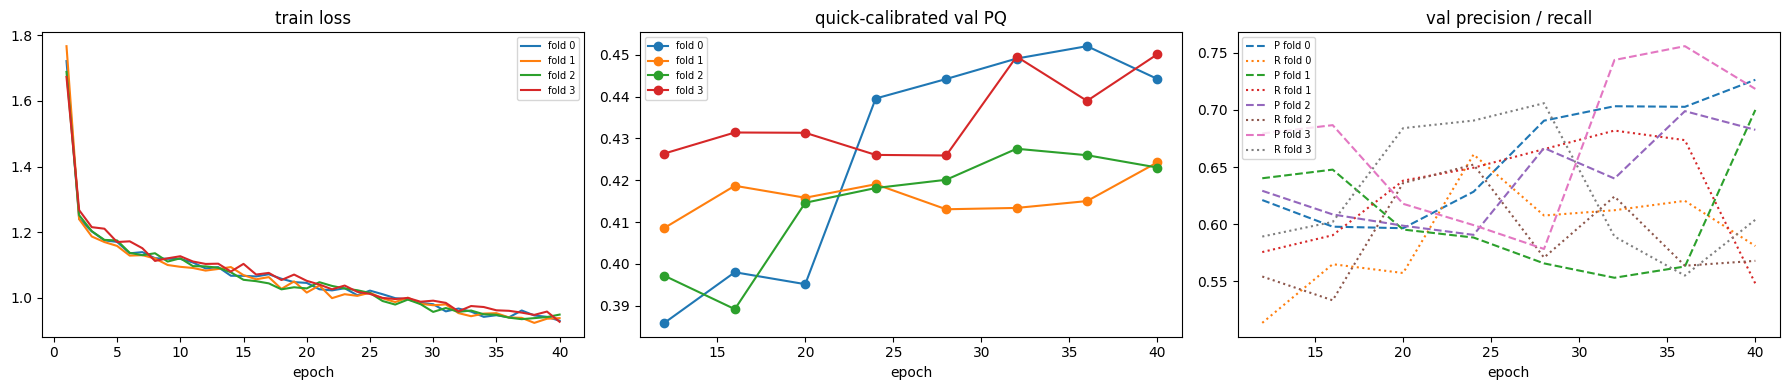

In [19]:
FOLD_INFO = {}
for _fold in CFG.folds_to_train:
    FOLD_INFO[_fold] = train_fold(_fold)
TRAINED_FOLDS = sorted(int(p.parent.name.replace("fold", "")) for p in RUN.glob("fold*/done.json"))
print("Trained folds:", TRAINED_FOLDS)
if not TRAINED_FOLDS:
    raise RuntimeError("No trained fold found.")

_fig, _ax = plt.subplots(1, 3, figsize=(18, 4))
for f in TRAINED_FOLDS:
    hist = pd.read_csv(RUN / f"fold{f}" / "history.csv")
    _ax[0].plot(hist.epoch, hist["loss"], label=f"fold {f}")
    if "val_pq" in hist:
        h = hist.dropna(subset=["val_pq"])
        _ax[1].plot(h.epoch, h.val_pq, marker="o", label=f"fold {f}")
        _ax[2].plot(h.epoch, h.val_precision, "--", label=f"P fold {f}"); _ax[2].plot(h.epoch, h.val_recall, ":", label=f"R fold {f}")
_ax[0].set_title("train loss"); _ax[1].set_title("quick-calibrated val PQ"); _ax[2].set_title("val precision / recall")
for a in _ax:
    a.legend(fontsize=7); a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## Cell 19 — Out-of-fold probability maps with full D4 TTA (each JPEG predicted by the model that never trained on it)
Saved as compressed `.npz` on Drive (reused after disconnects) and as `.npy` on the local SSD for the CPU workers.

In [20]:
OOF_LOCAL, OOF_DRIVE = LOCAL_ROOT / "oof", RUN / "oof"
OOF_TAG = object_hash({"tta": list(CFG.tta_final), "tile": CFG.tile, "stride": CFG.stride})[:10]

def load_fold_model(fold):
    ck = torch.load(RUN / f"fold{fold}" / "best.pt", map_location="cpu", weights_only=False)
    model = to_device(build_model(ck["encoder"], pretrained=False))
    model.load_state_dict(ck["state_dict"])
    return model.eval()

def save_npz_to_drive(path, fg, ct):
    tmp = LOCAL_ROOT / "npz_tmp" / path.name
    tmp.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(tmp, fg=fg, ct=ct)
    copy_atomic(tmp, path)
    tmp.unlink(missing_ok=True)

OOF_PATHS, BEST_SHAS = {}, {}
_drive_writer = ThreadPoolExecutor(max_workers=2)
_pending = []
for fold in TRAINED_FOLDS:
    BEST_SHAS[fold] = json.loads((RUN / f"fold{fold}" / "done.json").read_text())["best_sha256"]
    names = FOLDS.loc[FOLDS.fold == fold, "file_name"].tolist()
    if DEBUG_EVAL_LIMIT:
        names = names[:DEBUG_EVAL_LIMIT]
    sub = f"fold{fold}_{BEST_SHAS[fold][:10]}_{OOF_TAG}"
    (OOF_LOCAL / sub).mkdir(parents=True, exist_ok=True); (OOF_DRIVE / sub).mkdir(parents=True, exist_ok=True)
    model = None
    for name in tqdm(names, desc=f"OOF fold {fold} ({len(CFG.tta_final)}x TTA)"):
        stem = Path(name).stem
        lf, lc, dz = OOF_LOCAL / sub / f"{stem}_fg.npy", OOF_LOCAL / sub / f"{stem}_ct.npy", OOF_DRIVE / sub / f"{stem}.npz"
        if not (lf.is_file() and lc.is_file()):
            if dz.is_file():
                with np.load(dz) as z:
                    fg, ct = z["fg"], z["ct"]
            else:
                if model is None:
                    model = load_fold_model(fold)
                img, flat = cached_arrays(cache_key("train", name), False)
                fg, ct = predict_maps([model], img, flat, CFG.tta_final)
                _pending.append(_drive_writer.submit(save_npz_to_drive, dz, fg, ct))
            save_npy_atomic(lf, fg); save_npy_atomic(lc, ct)
        OOF_PATHS[name] = (str(lf), str(lc))
    model = None
    gc.collect(); torch.cuda.empty_cache()
for p in _pending:
    p.result()
_drive_writer.shutdown()
OOF_NAMES = sorted(OOF_PATHS)
print("OOF maps ready for", len(OOF_NAMES), "JPEGs")

OOF fold 0 (8x TTA):   0%|          | 0/177 [00:00<?, ?it/s]

OOF fold 1 (8x TTA):   0%|          | 0/177 [00:00<?, ?it/s]

OOF fold 2 (8x TTA):   0%|          | 0/177 [00:00<?, ?it/s]

OOF fold 3 (8x TTA):   0%|          | 0/176 [00:00<?, ?it/s]

OOF maps ready for 707 JPEGs


## Cell 20 — Calibrate instance geometry x filters on ALL out-of-fold JPEGs (exact global PQ, per annotator record)

In [21]:
CAL_GEOMS = [(float(a), b if b is None else float(b), int(c)) for a, b, c in product(CFG.grid_t_low, CFG.grid_contact, CFG.grid_offset)]
CAL_FILTERS = [(float(a), float(b), int(c)) for a, b, c in product(CFG.grid_t_high, CFG.grid_mean, CFG.grid_area)]
CAL_KEY = object_hash({"impl": "v3-cal-1", "shas": BEST_SHAS, "oof": OOF_TAG, "geoms": CAL_GEOMS,
                       "filters": CAL_FILTERS, "names": OOF_NAMES, "fill": CFG.fill_holes,
                       "core": CFG.min_core_area, "assign": CFG.contact_assign_radius, "conn": CFG.connectivity})
CAL_NPZ, CAL_JSON = RUN / "calibration_v3_per_image.npz", RUN / "calibration_v3.json"
if CAL_JSON.exists() and CAL_NPZ.exists() and json.loads(CAL_JSON.read_text()).get("key") == CAL_KEY:
    with np.load(CAL_NPZ) as z:
        PER_IMAGE = {n: z["stats"][i].astype(np.float64) for i, n in enumerate(z["names"].tolist())}
    print("Reusing calibration from Drive")
else:
    pool = get_pool()
    tasks = [(n, OOF_PATHS[n][0], OOF_PATHS[n][1], CAL_GEOMS, CAL_FILTERS) for n in OOF_NAMES]
    PER_IMAGE = {}
    for name, out in tqdm(pool.map(score_image_grid, tasks, chunksize=1), total=len(tasks),
                          desc=f"Calibration grid ({len(CAL_GEOMS)} geometries x {len(CAL_FILTERS)} filters)"):
        PER_IMAGE[name] = out
    tmp = LOCAL_ROOT / "calibration_tmp.npz"
    np.savez_compressed(tmp, names=np.array(OOF_NAMES), stats=np.stack([PER_IMAGE[n] for n in OOF_NAMES]).astype(np.float32))
    copy_atomic(tmp, CAL_NPZ)
    write_json(CAL_JSON, {"key": CAL_KEY, "geoms": CAL_GEOMS, "filters": CAL_FILTERS})

def subset_total(names):
    names = [n for n in names if n in PER_IMAGE]
    return sum((PER_IMAGE[n] for n in names), np.zeros((len(CAL_GEOMS), len(CAL_FILTERS), 5)))

GRID_TABLE = stats_table(subset_total(OOF_NAMES), CAL_GEOMS, CAL_FILTERS)
GRID_TABLE.to_csv(RUN / "calibration_v3.csv", index=False)
BEST_GRID = pick_best(GRID_TABLE)
GEOM, GRID_FILTER = as_geom(BEST_GRID), as_filter(BEST_GRID)
GI, FI = CAL_GEOMS.index(GEOM), CAL_FILTERS.index(GRID_FILTER)
show = ["t_low", "contact", "offset", "t_high", "min_mean", "min_area", "pq", "sq", "rq", "precision", "recall", "tp", "fp", "fn"]
print("Top 12 OOF recipes:"); print(GRID_TABLE.sort_values("pq", ascending=False)[show].head(12).to_string(index=False))
print("\nBest filter per geometry (effect of t_low / contact split / boundary offset):")
print(GRID_TABLE.loc[GRID_TABLE.groupby(["t_low", "contact", "offset"], dropna=False).pq.idxmax()][show]
      .sort_values("pq", ascending=False).to_string(index=False))
print("\nSelected grid recipe:", {k: BEST_GRID[k] for k in show})

Reusing calibration from Drive
Top 12 OOF recipes:
 t_low  contact  offset  t_high  min_mean  min_area       pq       sq       rq  precision   recall   tp   fp   fn
   0.4      0.5      -1     0.5       0.7       128 0.446064 0.684736 0.651440   0.712424 0.600073 4920 1986 3279
   0.4      0.5      -1     0.7       0.7       128 0.446064 0.684736 0.651440   0.712424 0.600073 4920 1986 3279
   0.4      0.5      -1     0.6       0.7       128 0.446064 0.684736 0.651440   0.712424 0.600073 4920 1986 3279
   0.4      NaN      -1     0.7       0.7       128 0.446037 0.684740 0.651397   0.712321 0.600073 4920 1987 3279
   0.4      NaN      -1     0.5       0.7       128 0.446037 0.684740 0.651397   0.712321 0.600073 4920 1987 3279
   0.4      NaN      -1     0.6       0.7       128 0.446037 0.684740 0.651397   0.712321 0.600073 4920 1987 3279
   0.4      0.5      -1     0.6       0.7         0 0.446035 0.684736 0.651397   0.712321 0.600073 4920 1987 3279
   0.4      0.5      -1     0.5      

## Cell 21 — Learned instance scorer: predict each candidate's expected PQ contribution u = mean_records[IoU·1(IoU>0.5)]
Adding one candidate adds 0.5 to the PQ denominator per record whether or not it matches, and adds its IoU to the numerator only
if it matches. So keeping it raises PQ iff u > PQ/2 (for unique matches). We cross-fit a gradient-boosted regressor by fold
(no candidate is scored by a model that saw its image), pick tau by exact OOF PQ, and use it only if it beats the grid filter.

In [22]:
GRID_PQ = float(BEST_GRID["pq"])
METHOD, TAU, FINAL_SCORER, SCORER_PQ = "grid", None, None, None
SCORER_PATH = RUN / "scorer_v3.pkl"
if CFG.use_learned_scorer:
    scorer_key = object_hash({"cal": CAL_KEY, "geom": GEOM, "pre": [CFG.scorer_prefilter_max, CFG.scorer_prefilter_area],
                              "taus": list(CFG.scorer_taus), "impl": "v3-scorer-1"})
    if SCORER_PATH.exists():
        with open(SCORER_PATH, "rb") as f:
            saved = pickle.load(f)
        if saved.get("key") == scorer_key:
            METHOD, TAU, FINAL_SCORER, SCORER_PQ = saved["method"], saved["tau"], saved["model"], saved["scorer_pq"]
            print("Reusing scorer from Drive:", METHOD, "tau", TAU, "OOF PQ", SCORER_PQ)
        else:
            saved = None
    else:
        saved = None
    if saved is None:
        pool = get_pool()
        rows = list(tqdm(pool.map(scorer_rows, [(n, *OOF_PATHS[n], GEOM) for n in OOF_NAMES], chunksize=1),
                         total=len(OOF_NAMES), desc="Candidate features (OOF)"))
        X = np.concatenate([r[1] for r in rows]) if rows else np.zeros((0, len(FEATURES)))
        y = np.concatenate([r[3] for r in rows]) if rows else np.zeros(0)
        counts = [len(r[3]) for r in rows]
        owner = np.repeat(np.arange(len(rows)), counts)
        if len(TRAINED_FOLDS) >= 2:
            grp_of_img = np.array([FOLD_OF[r[0]] for r in rows])
        else:
            grp_of_img = np.array([int(hashlib.sha256(r[0].encode()).hexdigest()[:6], 16) % 3 for r in rows])
        grp = grp_of_img[owner]
        def make_hgb():
            return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                                 min_samples_leaf=40, l2_regularization=1.0, random_state=CFG.seed)
        u = np.zeros(len(y))
        for g in np.unique(grp):
            tr = grp != g
            if tr.sum() < 200 or (~tr).sum() == 0:
                continue
            u[~tr] = make_hgb().fit(X[tr], y[tr]).predict(X[~tr])
        offsets = np.r_[0, np.cumsum(counts)]
        tau_rows = []
        for tau in CFG.scorer_taus:
            total = np.zeros(5)
            for i, r in enumerate(rows):
                keep = u[offsets[i]:offsets[i + 1]] >= tau
                for iou in r[4]:
                    total += match_stats(iou[:, keep])
            tau_rows.append({"tau": float(tau), **summarize(total)})
        TAU_TABLE = pd.DataFrame(tau_rows)
        TAU_TABLE.to_csv(RUN / "scorer_tau_v3.csv", index=False)
        best_tau = TAU_TABLE.sort_values("pq", ascending=False).iloc[0]
        SCORER_PQ, TAU = float(best_tau.pq), float(best_tau.tau)
        print(TAU_TABLE[["tau", "pq", "sq", "rq", "precision", "recall", "tp", "fp", "fn"]].to_string(index=False))
        print(f"Candidates: {len(y)} | cross-fitted scorer OOF PQ {SCORER_PQ:.4f} at tau={TAU} "
              f"(theory: tau ~ PQ/2 = {SCORER_PQ / 2:.3f}) vs grid filter {GRID_PQ:.4f}")
        if SCORER_PQ > GRID_PQ + CFG.scorer_min_gain:
            METHOD = "scorer"
            FINAL_SCORER = make_hgb().fit(X, y)
        with open(SCORER_PATH.with_suffix(".tmp"), "wb") as f:
            pickle.dump({"key": scorer_key, "method": METHOD, "tau": TAU, "model": FINAL_SCORER,
                         "scorer_pq": SCORER_PQ, "features": FEATURES}, f)
        os.replace(SCORER_PATH.with_suffix(".tmp"), SCORER_PATH)
print(f"Selected instance filter: {METHOD.upper()}  (grid OOF PQ {GRID_PQ:.4f}"
      + (f", scorer OOF PQ {SCORER_PQ:.4f}" if SCORER_PQ is not None else "") + ")")

Reusing scorer from Drive: scorer tau 0.25 OOF PQ 0.4484275231343933
Selected instance filter: SCORER  (grid OOF PQ 0.4461, scorer OOF PQ 0.4484)


## Cell 22 — Freeze the V3 recipe; OOF report (overall, per fold, V2-comparable subsets) and error decomposition

In [23]:
RECIPE = {"implementation": "sfsc-v3-unet", "architecture": CFG.architecture, "encoder": RESOLVED_ENCODER,
          "folds": TRAINED_FOLDS, "checkpoints_sha256": BEST_SHAS, "folds_sha256": FOLDS_SHA, "annotation_sha256": ANN_SHA,
          "tta": list(CFG.tta_final), "tile": CFG.tile, "stride": CFG.stride,
          "geometry": {"t_low": GEOM[0], "contact": GEOM[1], "offset": GEOM[2], "fill_holes": CFG.fill_holes,
                       "min_core_area": CFG.min_core_area, "contact_assign_radius": CFG.contact_assign_radius,
                       "connectivity": CFG.connectivity},
          "method": METHOD, "grid_filter": {"t_high": GRID_FILTER[0], "min_mean": GRID_FILTER[1], "min_area": GRID_FILTER[2]},
          "scorer_tau": TAU, "scorer_prefilter": [CFG.scorer_prefilter_max, CFG.scorer_prefilter_area],
          "oof_pq_grid": GRID_PQ, "oof_pq_scorer": SCORER_PQ, "oracles": ORACLES,
          "note": "Calibrated on single-model OOF maps; the test ensemble averages folds (slightly smoother maps)."}
RECIPE_SHA = object_hash(RECIPE)
write_json(RUN / "frozen_recipe_v3.json", {"sha256": RECIPE_SHA, "recipe": RECIPE})
print("Frozen recipe", RECIPE_SHA[:16], "| geometry", RECIPE["geometry"], "| method", METHOD)

def apply_recipe(fg, ct, img, flat):
    lab, n = geometry_labels(fg, ct, GEOM)
    feats, area = component_features(lab, n, fg, ct, img, flat)
    if METHOD == "scorer" and n:
        keep = prefilter_keep(feats, area)
        if keep.any():
            u = np.zeros(n)
            u[keep] = FINAL_SCORER.predict(feats[keep])
            keep &= u >= TAU
    else:
        keep = grid_keep(feats, area, GRID_FILTER)
    lut = np.zeros(n + 1, np.int32)
    ids = np.flatnonzero(keep) + 1
    lut[ids] = np.arange(1, len(ids) + 1, dtype=np.int32)
    return lut[lab], len(ids), area[keep], feats[keep]

SIZE_EDGES = (500, 1500, 5000)
def size_bucket(a):
    return ("tiny" if a < SIZE_EDGES[0] else "small" if a < SIZE_EDGES[1] else "medium" if a < SIZE_EDGES[2] else "large")
def radial_bucket(r):
    return "centre(<0.6)" if r < 0.6 else ("mid(0.6-0.85)" if r < 0.85 else "limb(>=0.85)")

def error_task(task):
    name, fgp, ctp = task
    fg, ct = load_maps(fgp, ctp)
    img, flat = cached_arrays(cache_key("train", name), False)
    lab, n, area, feats = apply_recipe(fg, ct, img, flat)
    recs = GT_INDEX[name]["records"]
    mats = overlap_matrices(lab, n, area, GT_INDEX[name])
    stats, gt_rows, pred_rows = np.zeros(5), [], []
    for ri, ((inter, iou), rec) in enumerate(zip(mats, recs)):
        stats += match_stats(iou)
        pairs = match_pairs(iou)
        mg, mp_ = {a for a, _, _ in pairs}, {b for _, b, _ in pairs}
        for j, idx in enumerate(rec["idx"]):
            a_gt = rec["area"][j]
            rad = math.hypot(YY_FLAT[idx].mean() - CY, XX_FLAT[idx].mean() - CX) / DISK_R
            best = float(iou[j].max()) if n else 0.0
            if j in mg:
                cat = "matched"
            else:
                cover = inter[j] / a_gt if n else np.zeros(0)
                c_best = int(np.argmax(inter[j])) if n and inter[j].max() > 0 else -1
                merged = c_best >= 0 and any(k != j and inter[k, c_best] >= 0.2 * rec["area"][k] for k in range(len(rec["idx"])))
                if n and (cover >= 0.2).sum() >= 2:
                    cat = "fragmented"
                elif merged:
                    cat = "merged"
                elif best >= 0.1:
                    cat = "near_miss(0.1-0.5)"
                else:
                    cat = "missed(<0.1)"
            gt_rows.append({"file_name": name, "record": ri, "area": a_gt, "size": size_bucket(a_gt),
                            "radial": radial_bucket(rad), "best_iou": best, "category": cat, "n_records": len(recs)})
        for c in range(n):
            best = float(iou[:, c].max()) if iou.shape[0] else 0.0
            cat = "tp" if c in mp_ else ("near_miss_fp" if best >= 0.1 else "spurious_fp")
            pred_rows.append({"file_name": name, "record": ri, "area": area[c], "size": size_bucket(area[c]),
                              "radial": radial_bucket(float(feats[c, F_IDX["radial"]])), "best_iou": best, "category": cat})
    return name, stats, gt_rows, pred_rows

pool = get_pool(refresh=True)   # workers must see apply_recipe / FINAL_SCORER
PER_FILE_STATS, GT_ROWS, PRED_ROWS = {}, [], []
for name, st, g, p in tqdm(pool.map(error_task, [(n, *OOF_PATHS[n]) for n in OOF_NAMES], chunksize=1),
                           total=len(OOF_NAMES), desc="OOF error decomposition (final recipe)"):
    PER_FILE_STATS[name] = st; GT_ROWS += g; PRED_ROWS += p
GT_DF, PRED_DF = pd.DataFrame(GT_ROWS), pd.DataFrame(PRED_ROWS)
DIAG = RUN / "diagnostics"; DIAG.mkdir(exist_ok=True)
GT_DF.to_csv(DIAG / "oof_gt_instances.csv", index=False); PRED_DF.to_csv(DIAG / "oof_predictions.csv", index=False)

def pq_of(names):
    st = sum((PER_FILE_STATS[n] for n in names if n in PER_FILE_STATS), np.zeros(5))
    return summarize(st)

def fmt(d):
    return {k: (round(v, 4) if isinstance(v, float) else v) for k, v in d.items()}

REPORT = {"overall_oof": pq_of(OOF_NAMES)}
for f in TRAINED_FOLDS:
    REPORT[f"fold{f}"] = pq_of(FOLDS.loc[FOLDS.fold == f, "file_name"])
for subset in ("dev", "holdout"):
    names = FOLDS.loc[FOLDS.v1_split == subset, "file_name"].tolist()
    if names:
        REPORT[f"V1_{subset}_subset"] = pq_of(names)
REPORT["single_annotator_jpegs"] = pq_of([n for n in OOF_NAMES if len(RECORD_IDS_BY_FILE[n]) == 1])
REPORT["multi_annotator_jpegs"] = pq_of([n for n in OOF_NAMES if len(RECORD_IDS_BY_FILE[n]) > 1])
write_json(DIAG / "oof_report.json", {"recipe_sha256": RECIPE_SHA, "report": REPORT, "oracles": ORACLES})
for k, v in REPORT.items():
    print(f"{k:28s}", fmt(v))
print("\nReference: V2 calibrated dev PQ 0.4014 (V1 dev subset), V2 holdout 0.4304 (V1 holdout subset).")
print("Note: V3 OOF on those subsets comes from fold models that did not train on them, but trained on more data overall.")

if len(GT_DF):
    print("\nGround-truth outcome by size (row %):")
    print((pd.crosstab(GT_DF["size"], GT_DF.category, normalize="index") * 100).round(1).to_string())
    print("\nGround-truth outcome by disk position (row %):")
    print((pd.crosstab(GT_DF.radial, GT_DF.category, normalize="index") * 100).round(1).to_string())
if len(PRED_DF):
    print("\nPrediction outcome by size (counts):")
    print(pd.crosstab(PRED_DF["size"], PRED_DF.category, margins=True).to_string())
print("\nOracles:", {k: (fmt(v) if v else v) for k, v in ORACLES.items()})

Frozen recipe 2d972709058d53bf | geometry {'t_low': 0.4, 'contact': 0.5, 'offset': -1, 'fill_holes': True, 'min_core_area': 16, 'contact_assign_radius': 6.0, 'connectivity': 8} | method scorer


OOF error decomposition (final recipe):   0%|          | 0/707 [00:00<?, ?it/s]

overall_oof                  {'pq': 0.486, 'sq': 0.6804, 'rq': 0.7142, 'precision': 0.7824, 'recall': 0.6569, 'tp': 5386, 'fp': 1498, 'fn': 2813, 'records': 1154}
fold0                        {'pq': 0.4929, 'sq': 0.6849, 'rq': 0.7197, 'precision': 0.7875, 'recall': 0.6626, 'tp': 1290, 'fp': 348, 'fn': 657, 'records': 288}
fold1                        {'pq': 0.4749, 'sq': 0.6797, 'rq': 0.6986, 'precision': 0.7711, 'recall': 0.6386, 'tp': 1297, 'fp': 385, 'fn': 734, 'records': 291}
fold2                        {'pq': 0.4755, 'sq': 0.6786, 'rq': 0.7007, 'precision': 0.7736, 'recall': 0.6403, 'tp': 1353, 'fp': 396, 'fn': 760, 'records': 292}
fold3                        {'pq': 0.5004, 'sq': 0.6788, 'rq': 0.7372, 'precision': 0.7967, 'recall': 0.686, 'tp': 1446, 'fp': 369, 'fn': 662, 'records': 283}
V1_dev_subset                {'pq': 0.4753, 'sq': 0.6796, 'rq': 0.6994, 'precision': 0.7818, 'recall': 0.6326, 'tp': 663, 'fp': 185, 'fn': 385, 'records': 152}
V1_holdout_subset            {'pq'

## Cell 23 — Test inference: 4-fold ensemble x D4 TTA -> frozen recipe -> COCO-RLE submission
Probability maps are also saved to Drive (`test_probs/`) so post-processing can be re-run later without the GPU.

In [24]:
def sparse_component_rle(labels, label_id, slices):
    region = slices[label_id - 1]
    if region is None:
        raise ValueError(f"Missing component label {label_id}")
    ys, xs = region
    rows, cols = np.nonzero(labels[ys, xs] == label_id)
    if len(rows) == 0:
        raise ValueError("Empty predicted component")
    h, w = labels.shape
    positions = np.sort((cols + xs.start).astype(np.int64) * h + (rows + ys.start))
    boundaries = np.flatnonzero(np.diff(positions) != 1) + 1
    begins, ends = np.r_[0, boundaries], np.r_[boundaries, len(positions)]
    run_starts, run_ends = positions[begins], positions[ends - 1] + 1
    counts = [int(run_starts[0])]
    for i in range(len(run_starts)):
        counts.append(int(run_ends[i] - run_starts[i]))
        if i + 1 < len(run_starts):
            counts.append(int(run_starts[i + 1] - run_ends[i]))
    counts.append(int(h * w - run_ends[-1]))
    if sum(counts) != h * w:
        raise AssertionError("Broken sparse RLE")
    rle = json_rle(mask_api.frPyObjects({"size": [h, w], "counts": counts}, h, w))
    if int(mask_api.area(native_rle(rle))) != len(positions):
        raise AssertionError("Sparse RLE area mismatch")
    return rle

LOCAL_EXPORT, EXPORT = LOCAL_ROOT / "test_export", RUN / "test_export"
for d in (LOCAL_EXPORT / "binary_masks", LOCAL_EXPORT / "instance_masks", EXPORT, RUN / "test_probs"):
    d.mkdir(parents=True, exist_ok=True)
SUBMISSION_PATH = EXPORT / "submission.csv"
PROCESSED = []
if CFG.export_test:
    MODELS = [load_fold_model(f) for f in TRAINED_FOLDS]
    print(f"Ensemble: {len(MODELS)} fold models x {len(CFG.tta_final)} TTA ops")
    writer = ThreadPoolExecutor(max_workers=2); pend = []
    rows = []
    for name in tqdm(sorted(TEST_PATHS), desc="Test inference"):
        stem = Path(name).stem
        img, flat = cached_arrays(cache_key("test", name), False)
        fg, ct = predict_maps(MODELS, img, flat, CFG.tta_final)
        pend.append(writer.submit(save_npz_to_drive, RUN / "test_probs" / f"{stem}_{RECIPE_SHA[:8]}.npz", fg, ct))
        labels, n, _, _ = apply_recipe(fg, ct, np.asarray(img), np.asarray(flat))
        if n > np.iinfo(np.uint16).max:
            raise ValueError("Too many instances for uint16 PNG")
        slices = ndi.find_objects(labels)
        for i in range(1, n + 1):
            rows.append({"filament_id": f"{stem}_{i}", "segmentation_rle": sparse_component_rle(labels, i, slices)["counts"]})
        Image.fromarray((labels > 0).astype(np.uint8) * 255).save(LOCAL_EXPORT / "binary_masks" / f"{stem}.png")
        Image.fromarray(labels.astype(np.uint16)).save(LOCAL_EXPORT / "instance_masks" / f"{stem}.png")
        PROCESSED.append({"file_name": name, "filament_count": n})
    for p in pend:
        p.result()
    writer.shutdown()
    submission = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
    submission.to_csv(LOCAL_EXPORT / "submission.csv", index=False)
    copy_atomic(LOCAL_EXPORT / "submission.csv", SUBMISSION_PATH)
    write_json(EXPORT / "processed_images.json", {"recipe_sha256": RECIPE_SHA, "images": PROCESSED, "instances": len(rows)})
    print("Submission:", SUBMISSION_PATH)
    print("Instances:", len(rows), "| per image mean", round(len(rows) / max(len(PROCESSED), 1), 2),
          "| images with zero predictions:", sum(p["filament_count"] == 0 for p in PROCESSED))
    MODELS = None
    gc.collect(); torch.cuda.empty_cache()

Ensemble: 4 fold models x 8 TTA ops


Test inference:   0%|          | 0/180 [00:00<?, ?it/s]

/tmp/ipykernel_10658/1457952857.py:28: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  im = torch.from_numpy(np.ascontiguousarray(img_u8)).to(DEVICE).float() / 255.0


Submission: /content/drive/MyDrive/SFSC2026/outputs/sfsc_unet_v3/test_export/submission.csv
Instances: 1066 | per image mean 5.92 | images with zero predictions: 3


## Cell 24 — Audit: every CSV RLE decodes to exactly the saved instance PNGs, no overlaps, no empty masks

In [25]:
if CFG.export_test:
    table = pd.read_csv(SUBMISSION_PATH, dtype=str, keep_default_na=False)
    if list(table.columns) != ["filament_id", "segmentation_rle"]:
        raise ValueError("Submission CSV schema mismatch")
    if table.filament_id.duplicated().any():
        raise ValueError("Duplicate filament IDs")
    by_stem = defaultdict(list)
    for row in table.itertuples(index=False):
        stem, suffix = row.filament_id.rsplit("_", 1)
        by_stem[stem].append((int(suffix), row.segmentation_rle))
    for proc in tqdm(PROCESSED, desc="Audit submission"):
        stem = Path(proc["file_name"]).stem
        saved = np.asarray(Image.open(LOCAL_EXPORT / "instance_masks" / f"{stem}.png")).astype(np.uint16)
        rebuilt = np.zeros((H, W), np.uint16)
        found = by_stem.get(stem, [])
        if len(found) != proc["filament_count"]:
            raise AssertionError(f"Wrong instance count for {stem}")
        for suffix, counts in found:
            m = decode_mask({"size": [H, W], "counts": counts})
            if not m.any() or np.any(rebuilt[m]):
                raise AssertionError(f"Empty/overlapping instance {stem}_{suffix}")
            rebuilt[m] = suffix
        if not np.array_equal(rebuilt, saved):
            raise AssertionError(f"RLE / PNG disagreement: {stem}")
    archive = LOCAL_ROOT / "test_masks_v3.zip"
    with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=2) as z:
        for f in sorted(LOCAL_EXPORT.rglob("*.png")):
            z.write(f, f.relative_to(LOCAL_EXPORT))
    copy_atomic(archive, EXPORT / "test_masks_v3.zip")
    write_json(EXPORT / "serialization_audit.json", {"passed": True, "images": len(PROCESSED), "instances": len(table),
                                                     "submission_sha256": hash_file(SUBMISSION_PATH), "recipe_sha256": RECIPE_SHA})
    print("Audit passed: all", len(table), "instances match their PNG masks exactly")

Audit submission:   0%|          | 0/180 [00:00<?, ?it/s]

Audit passed: all 1066 instances match their PNG masks exactly


## Cell 25 — Manifest and environment

In [26]:
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True)
(RUN / "environment_v3.txt").write_text(freeze.stdout)
manifest = {"algorithm": f"V3 {CFG.architecture}-{RESOLVED_ENCODER} {len(TRAINED_FOLDS)}-fold ensemble",
            "recipe_sha256": RECIPE_SHA, "folds": TRAINED_FOLDS,
            "fold_quick_val_pq": {f: json.loads((RUN / f"fold{f}" / "done.json").read_text())["best_pq"] for f in TRAINED_FOLDS},
            "oof_report": REPORT, "oracles": ORACLES, "method": METHOD, "geometry": RECIPE["geometry"],
            "grid_filter": RECIPE["grid_filter"], "scorer_tau": TAU,
            "micro_batch": MICRO, "accumulation": ACCUM, "gpu": torch.cuda.get_device_name(0), "amp": str(AMP_DTYPE),
            "python": platform.python_version(), "torch": torch.__version__, "smp": smp.__version__, "timm": timm.__version__,
            "submission": str(SUBMISSION_PATH) if CFG.export_test else None,
            "submission_sha256": hash_file(SUBMISSION_PATH) if CFG.export_test and SUBMISSION_PATH.exists() else None}
write_json(RUN / "manifest_v3.json", manifest)
print(json.dumps({k: manifest[k] for k in ("algorithm", "method", "geometry", "grid_filter", "scorer_tau", "submission")},
                 indent=2, default=str))
print("OOF PQ (all JPEGs):", fmt(REPORT["overall_oof"]))
print("Artifacts:", RUN)

{
  "algorithm": "V3 Unet-tu-tf_efficientnetv2_s.in21k_ft_in1k 4-fold ensemble",
  "method": "scorer",
  "geometry": {
    "t_low": 0.4,
    "contact": 0.5,
    "offset": -1,
    "fill_holes": true,
    "min_core_area": 16,
    "contact_assign_radius": 6.0,
    "connectivity": 8
  },
  "grid_filter": {
    "t_high": 0.5,
    "min_mean": 0.7,
    "min_area": 128
  },
  "scorer_tau": 0.25,
  "submission": "/content/drive/MyDrive/SFSC2026/outputs/sfsc_unet_v3/test_export/submission.csv"
}
OOF PQ (all JPEGs): {'pq': 0.486, 'sq': 0.6804, 'rq': 0.7142, 'precision': 0.7824, 'recall': 0.6569, 'tp': 5386, 'fp': 1498, 'fn': 2813, 'records': 1154}
Artifacts: /content/drive/MyDrive/SFSC2026/outputs/sfsc_unet_v3
